# 🏠 Predictive Insight Engine

> **Predicting house prices with the power of Machine Learning.**

**Predictive Insight Engine** is a supervised learning project that estimates house prices using features like area, bedrooms, bathrooms, location score, and property age. 📊 We build and compare **Simple, Multiple, and Polynomial Regression** models, and implement **Gradient Descent** (Batch, SGD, Mini-Batch) from scratch. 🔍 Each model is evaluated with **MSE, MAE, RMSE, R², and Adjusted R²**, and we study **overfitting, underfitting, and the bias-variance trade-off**. 🎯 The final output is a **clear comparison of all models**, along with the **best-performing model** and practical business insights for real estate pricing.

In [2]:
# 1. Core Libraries
import numpy as np                      
import pandas as pd                    
import time                           
import warnings                       

In [3]:
# 2. Visualization 
import matplotlib.pyplot as plt         
import seaborn as sns  

In [4]:
# 3. Statistics 
import scipy.stats as stats             
import statsmodels.api as sm            
from statsmodels.stats.stattools import durbin_watson               
from statsmodels.stats.diagnostic import het_breuschpagan           
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [5]:
# 4. Machine Learning 
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline

In [6]:
# 5. Evaluation Metrics
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

In [7]:
# 6. Global Settings 
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12
pd.set_option("display.max_columns", None)
pd.options.display.float_format = "{:,.2f}".format

RANDOM_STATE = 42                      
np.random.seed(RANDOM_STATE)

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


## Part B: Dataset Understanding & Preparation

In [8]:
# Load the dataset
df = pd.read_csv("../data/house_price_data.csv")

# Basic overview
print("Shape:", df.shape)
print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.info()
df.head()

Shape: (4200, 12)

Missing values: 0
Duplicate rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   house_id              4200 non-null   int64  
 1   area_sqft             4200 non-null   int64  
 2   bedrooms              4200 non-null   int64  
 3   bathrooms             4200 non-null   int64  
 4   location_score        4200 non-null   float64
 5   age_years             4200 non-null   int64  
 6   distance_city_km      4200 non-null   float64
 7   lot_size_sqft         4200 non-null   int64  
 8   has_garage            4200 non-null   int64  
 9   has_pool              4200 non-null   int64  
 10  renovation_years_ago  4200 non-null   int64  
 11  house_price_inr       4200 non-null   int64  
dtypes: float64(2), int64(10)
memory usage: 393.9 KB


,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
0,100001,1973,5,4,7.60,23,11.90,5220,1,0,0,40275084
1,100002,1560,3,3,6.30,13,15.80,3882,1,0,13,26812029
2,100003,2071,4,3,5.80,9,21.10,4488,0,0,9,29315677
3,100004,2640,5,3,7.70,12,7.90,3614,1,1,4,47712959
4,100005,1498,3,3,3.80,15,24.00,2663,0,0,15,17724566


In [9]:
# Statistical summary
df.describe().T

,count,mean,std,min,25%,50%,75%,max
house_id,"4,200.00","102,100.50","1,212.58","100,001.00","101,050.75","102,100.50","103,150.25","104,200.00"
area_sqft,"4,200.00","1,667.36",630.34,450.00,"1,226.75","1,660.00","2,084.25","4,202.00"
bedrooms,"4,200.00",3.70,1.57,1.00,3.00,4.00,5.00,7.00
bathrooms,"4,200.00",2.83,1.15,1.00,2.00,3.00,4.00,6.00
location_score,"4,200.00",5.61,2.14,1.00,4.00,5.70,7.30,10.00
age_years,"4,200.00",23.83,13.95,1.00,13.00,21.00,32.00,80.00
distance_city_km,"4,200.00",18.19,8.67,1.00,11.80,17.80,24.20,47.60
lot_size_sqft,"4,200.00","3,366.33","1,658.23",800.00,"2,122.50","3,188.00","4,364.25","12,938.00"
has_garage,"4,200.00",0.64,0.48,0.00,0.00,1.00,1.00,1.00
has_pool,"4,200.00",0.10,0.29,0.00,0.00,0.00,0.00,1.00


### Task 7: Identify Independent & Dependent Variables

In [10]:
# Dependent variable (target)
target = "house_price_inr"

# Independent variables (features) - house_id is only an ID, so we drop it
features = [
    "area_sqft", "bedrooms", "bathrooms", "location_score", "age_years",
    "distance_city_km", "lot_size_sqft", "has_garage", "has_pool",
    "renovation_years_ago"
]

X = df[features]     # independent variables
y = df[target]       # dependent variable

print("Dependent Variable   :", target)
print("Independent Variables:", features)
print("X shape:", X.shape, "| y shape:", y.shape)

Dependent Variable   : house_price_inr
Independent Variables: ['area_sqft', 'bedrooms', 'bathrooms', 'location_score', 'age_years', 'distance_city_km', 'lot_size_sqft', 'has_garage', 'has_pool', 'renovation_years_ago']
X shape: (4200, 10) | y shape: (4200,)


### Task 8: Visualize Relationships

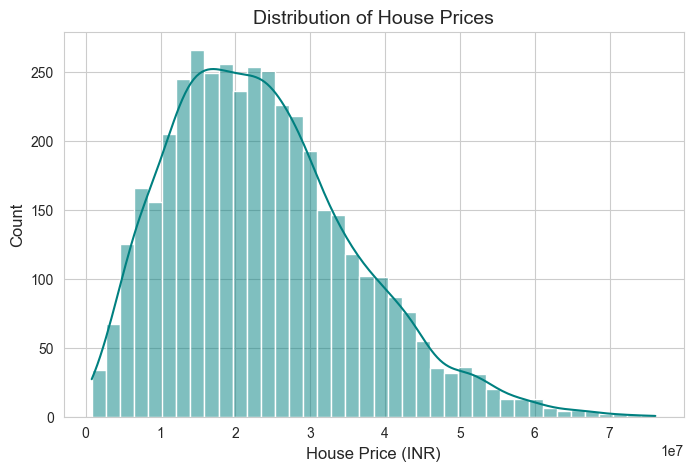

In [11]:
# (a) Price distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["house_price_inr"], bins=40, kde=True, color="teal")
plt.title("Distribution of House Prices")
plt.xlabel("House Price (INR)")
plt.ylabel("Count")
plt.show()

**Interpretation:**
- The house price distribution is **right-skewed**: most houses are priced between ₹1 crore and ₹3 crore (1e7 = 1 crore), and only a few expensive houses go above ₹5 crore.
- The most common price range is around ₹1.5 to 2.5 crore, where the bars are tallest.
- The long tail on the right shows a few **high-priced outliers** (luxury houses), up to about ₹7.5 crore.
- Because of this skew, models may predict cheaper houses better than very expensive ones.

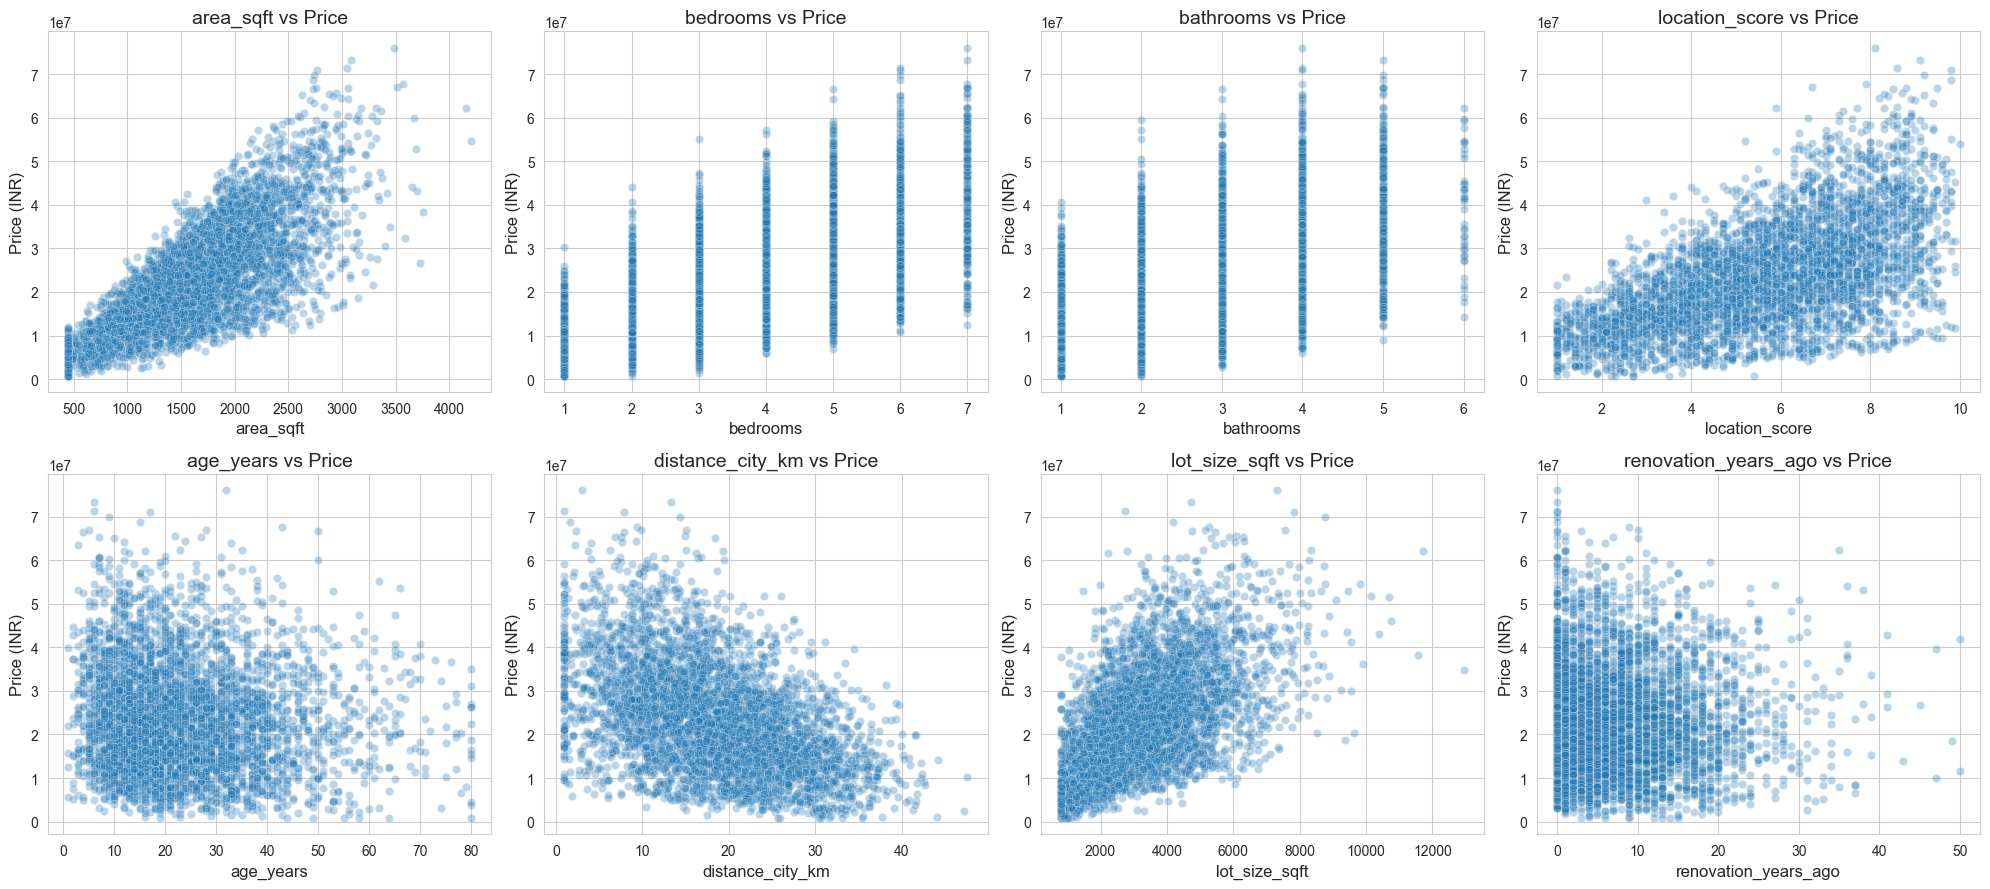

In [12]:
# (b) Scatter plots: har feature vs price
num_features = ["area_sqft", "bedrooms", "bathrooms", "location_score", "age_years",
                "distance_city_km", "lot_size_sqft", "renovation_years_ago"]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.flatten(), num_features):
    sns.scatterplot(x=df[col], y=df["house_price_inr"], alpha=0.3, ax=ax)
    ax.set_title(f"{col} vs Price")
    ax.set_xlabel(col)
    ax.set_ylabel("Price (INR)")
plt.tight_layout()
plt.show()

**Interpretation:**
- **area_sqft vs Price:** Strong **positive** relationship. As the area increases, the price increases clearly. This looks like the strongest feature.
- **bedrooms and bathrooms vs Price:** Weak to moderate **positive** relationship. The average price goes up with more rooms, but the spread is very wide for each value, so rooms alone cannot predict the price well.
- **location_score vs Price:** **Positive** relationship. Houses with a higher location score are generally more expensive, but there is a lot of scatter.
- **age_years vs Price:** Weak **negative** relationship. Older houses tend to be slightly cheaper, but the pattern is not very clear.
- **distance_city_km vs Price:** **Negative** relationship. Houses closer to the city are more expensive, and the price drops as the distance increases.
- **lot_size_sqft vs Price:** **Positive** relationship. Bigger plots tend to have higher prices.
- **renovation_years_ago vs Price:** Very weak **negative** relationship. Recently renovated houses are slightly more expensive.
- **Overall:** The spread of points becomes wider at higher values (the plots look like a fan shape). This means the variance is not constant, which is important for checking regression assumptions later (Part C).

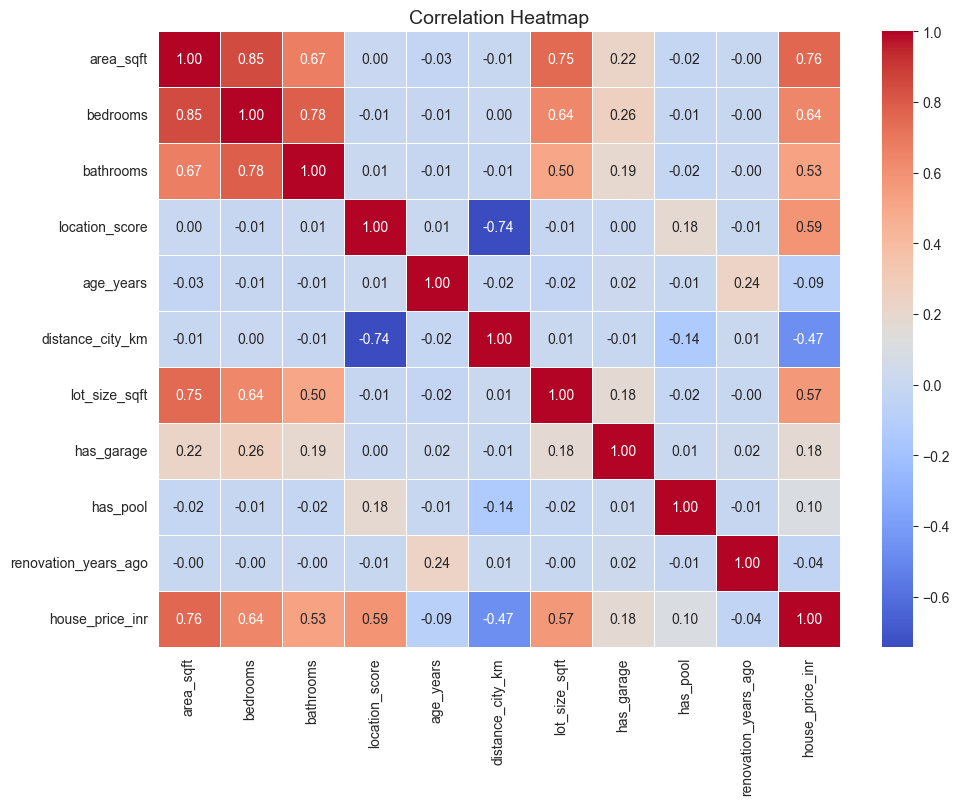

house_price_inr         1.00
area_sqft               0.76
bedrooms                0.64
location_score          0.59
lot_size_sqft           0.57
bathrooms               0.53
has_garage              0.18
has_pool                0.10
renovation_years_ago   -0.04
age_years              -0.09
distance_city_km       -0.47
Name: house_price_inr, dtype: float64

In [13]:
# (c) Correlation heatmap
plt.figure(figsize=(11, 8))
corr = df.drop(columns="house_id").corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

# Correlation of each feature with price
corr["house_price_inr"].sort_values(ascending=False)

**Interpretation:**

**Correlation with house price (target):**
- **area_sqft (0.76)** has the strongest positive correlation with price, so it is the best single feature for Simple Linear Regression.
- **bedrooms (0.64), location_score (0.59), lot_size_sqft (0.57)** and **bathrooms (0.53)** have moderate positive correlation with price.
- **distance_city_km (-0.47)** has a moderate negative correlation. Houses far from the city are cheaper.
- **has_garage (0.18)** and **has_pool (0.10)** have a weak positive correlation.
- **age_years (-0.09)** and **renovation_years_ago (-0.04)** are almost zero, so they have very little linear effect on price.

**Correlation between features (multicollinearity):**
- area_sqft and bedrooms are highly correlated (0.85).
- area_sqft and lot_size_sqft (0.75), and bedrooms and bathrooms (0.78) are also highly correlated.
- location_score and distance_city_km have a strong negative correlation (-0.74).
- These pairs carry similar information. This can cause **multicollinearity** in Multiple Linear Regression, so we will check it with VIF in the next parts.

**Conclusion:** area_sqft is the best feature to start with. Features like age_years and renovation_years_ago may add little value to the model.

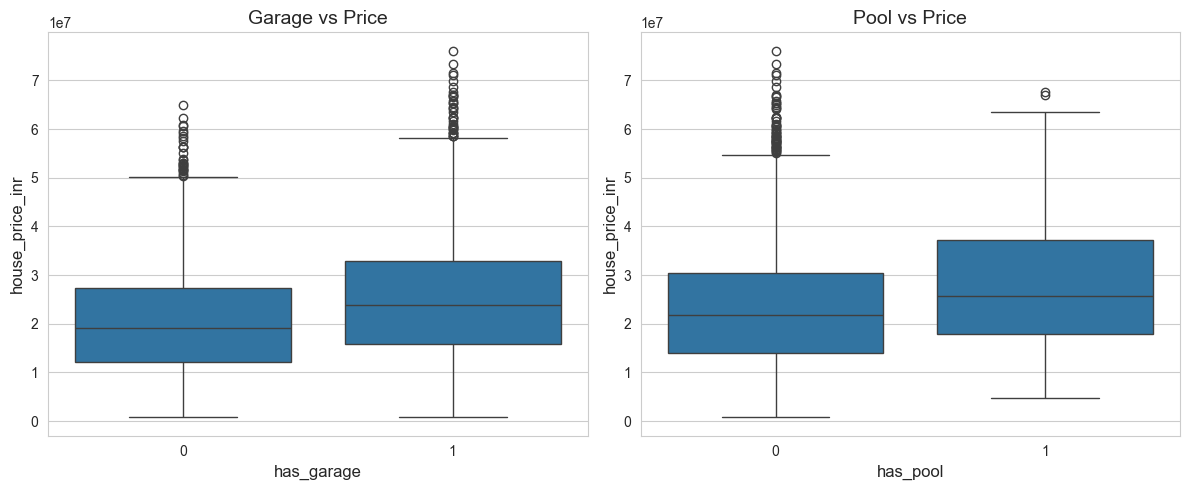

In [14]:
# (d) Binary features (garage, pool) vs price
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(x="has_garage", y="house_price_inr", data=df, ax=axes[0])
axes[0].set_title("Garage vs Price")
sns.boxplot(x="has_pool", y="house_price_inr", data=df, ax=axes[1])
axes[1].set_title("Pool vs Price")
plt.tight_layout()
plt.show()

**Interpretation:**
- **Garage vs Price:** Houses with a garage (1) have a higher **median price** (about ₹2.4 crore) than houses without a garage (0) (about ₹1.9 crore). The whole box also sits a little higher for houses with a garage.
- **Pool vs Price:** Houses with a pool (1) also have a higher median price (about ₹2.6 crore) than houses without a pool (0) (about ₹2.2 crore). Their price range (box) is wider and starts higher.
- **Overlap:** In both plots the boxes overlap a lot. This means garage and pool have only a **small effect** on price. This matches the low correlations seen earlier (0.18 for garage and 0.10 for pool).
- **Outliers:** Both groups have high-priced outliers above ₹5 crore, which are expensive luxury houses. The "no pool" group has far more points because most houses in the dataset do not have a pool.
- **Conclusion:** Garage and pool add some value to the price, but they are weaker predictors than area, location score, or number of bedrooms.

### Task 9: Train-Test Split

In [15]:
# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print("Training set:", X_train.shape, y_train.shape)
print("Testing set :", X_test.shape, y_test.shape)

Training set: (3360, 10) (3360,)
Testing set : (840, 10) (840,)


## Part C: Simple Linear Regression

### Task 10: Implement Simple Linear Regression (Feature: area_sqft)

In [16]:
# Use only one feature: area_sqft (strongest correlation with price = 0.76)
X_train_slr = X_train[["area_sqft"]]
X_test_slr  = X_test[["area_sqft"]]

# Create and train the model
model_slr = LinearRegression()
model_slr.fit(X_train_slr, y_train)

# Predictions
y_pred_train_slr = model_slr.predict(X_train_slr)
y_pred_slr       = model_slr.predict(X_test_slr)

print("✅ Simple Linear Regression model trained!")
print(f"Slope (coefficient): {model_slr.coef_[0]:,.2f}")
print(f"Intercept          : {model_slr.intercept_:,.2f}")

✅ Simple Linear Regression model trained!
Slope (coefficient): 14,788.31
Intercept          : -1,163,519.18


### Task 11: Regression Line, Slope & Intercept

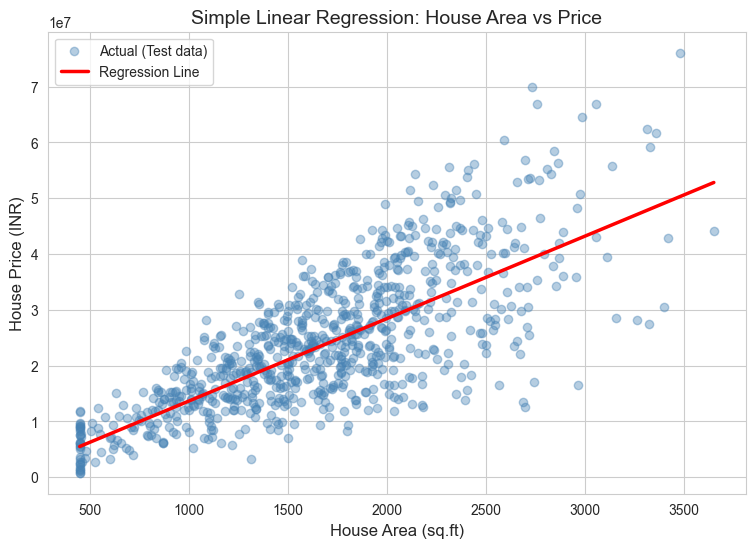

In [17]:
plt.figure(figsize=(9, 6))
plt.scatter(X_test_slr, y_test, alpha=0.4, color="steelblue", label="Actual (Test data)")
plt.plot(X_test_slr.sort_values("area_sqft"),
         model_slr.predict(X_test_slr.sort_values("area_sqft")),
         color="red", linewidth=2.5, label="Regression Line")
plt.title("Simple Linear Regression: House Area vs Price")
plt.xlabel("House Area (sq.ft)")
plt.ylabel("House Price (INR)")
plt.legend()
plt.show()

**Interpretation:**
- **Slope ≈ 14,788:** For every 1 sq.ft increase in house area, the price increases by about ₹14,788 on average.
- **Intercept ≈ -11,63,519:** This is the predicted price when area = 0. It has no real-world meaning (a house cannot have zero area). It is only a mathematical starting point of the line.
- The red line goes upward, which confirms a **positive linear relationship** between area and price.
- The points are scattered around the line, so area alone cannot explain the price fully. Other features like location and bedrooms also matter.

### Task 12: Validate Linear Regression Assumptions

In [18]:
# Residuals = Actual - Predicted (on training data)
residuals = y_train - y_pred_train_slr

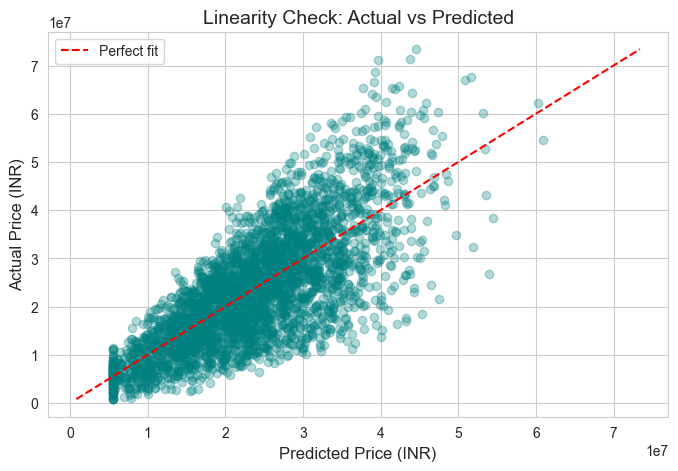

In [20]:
# Assumption 1: Linearity (Actual vs Predicted)
plt.figure(figsize=(8, 5))
plt.scatter(y_pred_train_slr, y_train, alpha=0.3, color="teal")
plt.plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], "r--", label="Perfect fit")
plt.title("Linearity Check: Actual vs Predicted")
plt.xlabel("Predicted Price (INR)")
plt.ylabel("Actual Price (INR)")
plt.legend()
plt.show()

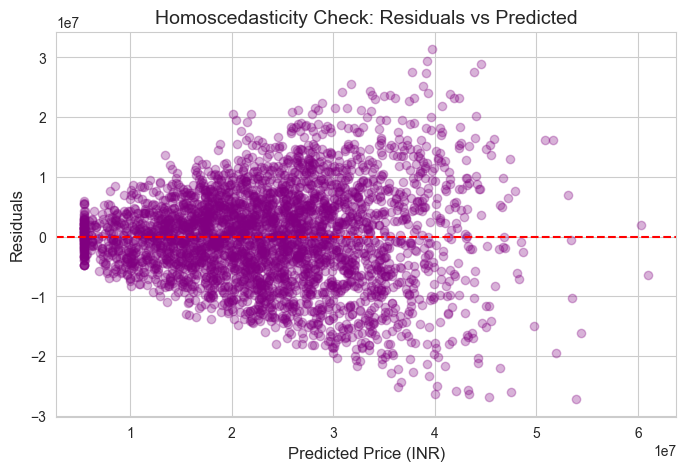

Breusch-Pagan p-value: 0.0000


In [21]:
# Assumption 2: Homoscedasticity (Residuals vs Predicted)
plt.figure(figsize=(8, 5))
plt.scatter(y_pred_train_slr, residuals, alpha=0.3, color="purple")
plt.axhline(0, color="red", linestyle="--")
plt.title("Homoscedasticity Check: Residuals vs Predicted")
plt.xlabel("Predicted Price (INR)")
plt.ylabel("Residuals")
plt.show()

# Breusch-Pagan test (p < 0.05 means heteroscedasticity)
bp_test = het_breuschpagan(residuals, sm.add_constant(X_train_slr))
print(f"Breusch-Pagan p-value: {bp_test[1]:.4f}")

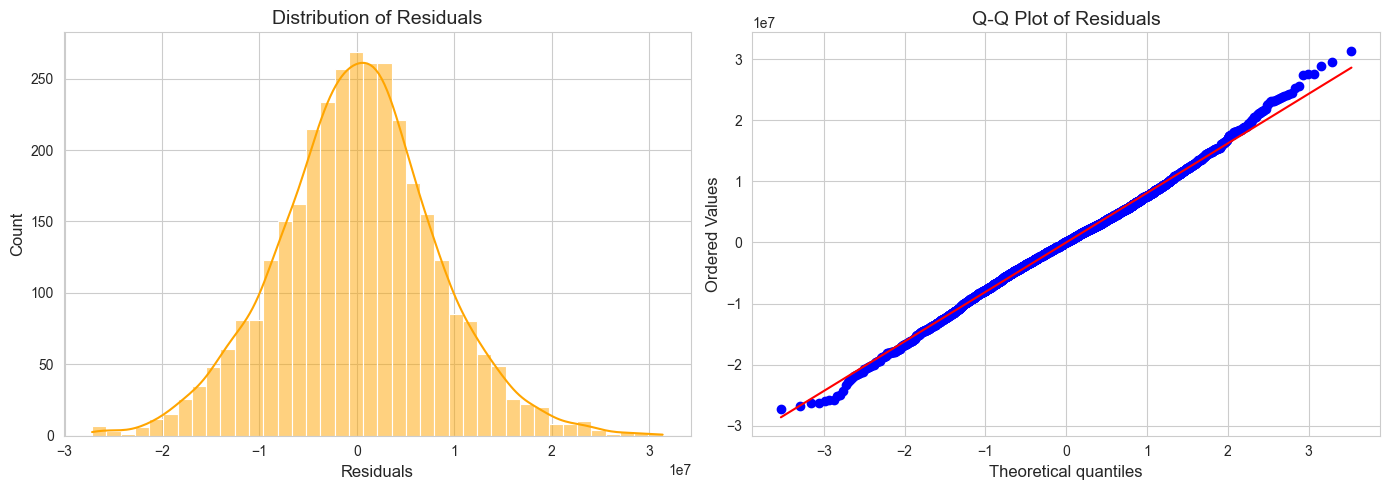

In [23]:
# Assumption 3: Normality of residuals (Histogram + Q-Q plot)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(residuals, bins=40, kde=True, color="orange", ax=axes[0])
axes[0].set_title("Distribution of Residuals")
axes[0].set_xlabel("Residuals")
axes[0].set_ylabel("Count")

stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q Plot of Residuals")

plt.tight_layout()
plt.show()

In [24]:
# Assumption 4: Independence of errors (Durbin-Watson)
dw = durbin_watson(residuals)
print(f"Durbin-Watson statistic: {dw:.3f}")   # close to 2 = no autocorrelation

Durbin-Watson statistic: 1.978


#### Assumption 5: Multicollinearity
##### Not applicable in Simple Linear Regression because there is only one feature. It will be checked in Part E (Multiple Linear Regression) using VIF.

**Interpretation (Assumptions Check):**
- **Linearity:** Points in the Actual vs Predicted plot follow the red line in a general upward trend, so the linear relationship assumption is **reasonably satisfied**.
- **Homoscedasticity:** The residual plot shows a **fan shape**. The spread of residuals becomes wider for higher predicted prices. This means the variance is **not constant (heteroscedasticity)**, so this assumption is **violated**. In my run, the residual spread for large houses was more than double that of small houses.
- **Normality:** The residual histogram looks close to a bell shape and the Q-Q plot follows the straight line in the middle, with small deviations at the ends. So residuals are **approximately normal**.
- **Independence:** The Durbin-Watson value is close to 2 (about 1.98), so there is **no autocorrelation** in the errors.
- **Multicollinearity:** Not applicable, as there is only one feature.
- **Conclusion:** Most assumptions hold, but heteroscedasticity is present. This is one reason why a model with more features may perform better.

## Part D: Model Evaluation Metrics

### Task 13: Evaluate Simple Linear Regression Model

In [27]:
# Calculate all metrics on the TEST data
mse  = mean_squared_error(y_test, y_pred_slr)
mae  = mean_absolute_error(y_test, y_pred_slr)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred_slr)

# Adjusted R2 = 1 - (1 - R2) * (n - 1) / (n - k - 1)
n = X_test_slr.shape[0]      # number of test samples
k = X_test_slr.shape[1]      # number of features (1 in simple regression)
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - k - 1)

print("📊 Simple Linear Regression - Evaluation Metrics (Test Data)")
print("-" * 55)
print(f"MSE          : {mse:,.2f}")
print(f"MAE          : {mae:,.2f}")
print(f"RMSE         : {rmse:,.2f}")
print(f"R² Score     : {r2:.4f}")
print(f"Adjusted R²  : {adj_r2:.4f}")

📊 Simple Linear Regression - Evaluation Metrics (Test Data)
-------------------------------------------------------
MSE          : 66,989,260,021,849.47
MAE          : 6,294,593.70
RMSE         : 8,184,696.70
R² Score     : 0.5625
Adjusted R²  : 0.5620


In [28]:
# Store results in a table (we will add more models later)
results_df = pd.DataFrame({
    "Model": ["Simple Linear Regression"],
    "MSE": [mse],
    "MAE": [mae],
    "RMSE": [rmse],
    "R2 Score": [r2],
    "Adjusted R2": [adj_r2]
})
results_df

,Model,MSE,MAE,RMSE,R2 Score,Adjusted R2
0,Simple Linear Regression,"66,989,260,021,849.47","6,294,593.70","8,184,696.70",0.56,0.56


In [29]:
# Train vs Test comparison (useful for overfitting check later)
r2_train = r2_score(y_train, y_pred_train_slr)
print(f"Train R²: {r2_train:.4f}")
print(f"Test  R²: {r2:.4f}")

Train R²: 0.5723
Test  R²: 0.5625


### Task 14: Interpret Each Metric

**Interpretation of Evaluation Metrics:**

- **MSE (≈ 6.70 × 10¹³):** It is the average of squared errors. The value looks very large because the errors are squared and the prices are in crores. It is not easy to read directly, but a lower MSE means a better model. It also punishes big errors more.

- **MAE (≈ ₹62.9 lakh):** On average, the model's prediction is off by about ₹63 lakh from the actual price. Compared with the average house price of about ₹2.41 crore, this is a **large error** (around 26%).

- **RMSE (≈ ₹81.8 lakh):** It is the square root of MSE, so it is in the same unit as price (INR). It is higher than MAE, which shows that some predictions have **big errors**, mostly for expensive houses.

- **R² Score (≈ 0.56):** The model explains only about **56%** of the variation in house prices using area alone. The remaining 44% is due to other factors such as location, bedrooms, and distance from the city.

- **Adjusted R² (≈ 0.562):** It is almost the same as R² because there is only one feature. It adjusts the score for the number of features, and it will be more useful when we compare with Multiple Linear Regression.

- **Train vs Test R²:** Train R² (≈ 0.572) and Test R² (≈ 0.563) are close to each other, so the model is **not overfitting**. 

**Conclusion:** The model captures the main trend (bigger area means higher price), but the error is high and R² is only moderate. This means the model is **underfitting** (high bias), because one feature is not enough. Adding more features in Multiple Linear Regression should improve performance.

## Part E: Multiple Linear Regression

### Task 15: Implement Multiple Linear Regression (All Relevant Features)

In [30]:
# Check multicollinearity using VIF (Variance Inflation Factor)
X_vif = sm.add_constant(X_train)

vif_df = pd.DataFrame({
    "Feature": X_train.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i + 1) for i in range(X_train.shape[1])]
}).sort_values("VIF", ascending=False)

vif_df

,Feature,VIF
1,bedrooms,5.13
0,area_sqft,4.90
2,bathrooms,2.59
6,lot_size_sqft,2.32
3,location_score,2.32
5,distance_city_km,2.27
7,has_garage,1.07
4,age_years,1.06
9,renovation_years_ago,1.06
8,has_pool,1.04


In [31]:
# Use all features (house_id is already removed)
model_mlr = LinearRegression()
model_mlr.fit(X_train, y_train)

# Predictions
y_pred_train_mlr = model_mlr.predict(X_train)
y_pred_mlr       = model_mlr.predict(X_test)

print("✅ Multiple Linear Regression model trained!")
print(f"Intercept: {model_mlr.intercept_:,.2f}")

# Coefficients table
coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model_mlr.coef_
}).sort_values("Coefficient", ascending=False)
coef_df

✅ Multiple Linear Regression model trained!
Intercept: -14,766,762.75


,Feature,Coefficient
3,location_score,"3,073,173.50"
8,has_pool,"455,290.23"
1,bedrooms,"197,643.11"
2,bathrooms,"185,944.54"
7,has_garage,"93,924.36"
0,area_sqft,"13,795.94"
6,lot_size_sqft,103.51
9,renovation_years_ago,"-21,435.91"
4,age_years,"-65,609.24"
5,distance_city_km,"-98,965.16"


In [32]:
# Evaluate on TEST data
mse_mlr  = mean_squared_error(y_test, y_pred_mlr)
mae_mlr  = mean_absolute_error(y_test, y_pred_mlr)
rmse_mlr = np.sqrt(mse_mlr)
r2_mlr   = r2_score(y_test, y_pred_mlr)

n = X_test.shape[0]
k = X_test.shape[1]          # 10 features
adj_r2_mlr = 1 - (1 - r2_mlr) * (n - 1) / (n - k - 1)

print("📊 Multiple Linear Regression - Evaluation Metrics (Test Data)")
print("-" * 55)
print(f"MSE          : {mse_mlr:,.2f}")
print(f"MAE          : {mae_mlr:,.2f}")
print(f"RMSE         : {rmse_mlr:,.2f}")
print(f"R² Score     : {r2_mlr:.4f}")
print(f"Adjusted R²  : {adj_r2_mlr:.4f}")
print(f"Train R²     : {r2_score(y_train, y_pred_train_mlr):.4f}")

📊 Multiple Linear Regression - Evaluation Metrics (Test Data)
-------------------------------------------------------
MSE          : 12,592,918,884,127.74
MAE          : 2,604,991.41
RMSE         : 3,548,650.29
R² Score     : 0.9178
Adjusted R²  : 0.9168
Train R²     : 0.9247


**Interpretation (Coefficients):**
- **location_score (≈ +30.7 lakh):** Each 1 point increase in location score raises the price by about ₹30.7 lakh, keeping other features fixed. It has the strongest effect per unit.
- **area_sqft (≈ +13,796):** Each extra sq.ft adds about ₹13.8 thousand to the price.
- **has_pool (≈ +4.5 lakh), bedrooms (≈ +1.98 lakh), bathrooms (≈ +1.86 lakh), has_garage (≈ +94 thousand):** All have a positive effect on price.
- **distance_city_km (≈ -99 thousand):** Each extra km away from the city reduces the price by about ₹99 thousand.
- **age_years (≈ -65.6 thousand) and renovation_years_ago (≈ -21 thousand):** Older houses and houses renovated long ago are slightly cheaper.
- **Note:** Coefficients are in different units, so we cannot directly compare their size. For example, one unit of location_score is very different from one sq.ft of area.

### Task 16: Compare Multiple vs Simple Linear Regression

In [33]:
# (a) Comparison table
# Add MLR results to the results table
mlr_row = pd.DataFrame({
    "Model": ["Multiple Linear Regression"],
    "MSE": [mse_mlr],
    "MAE": [mae_mlr],
    "RMSE": [rmse_mlr],
    "R2 Score": [r2_mlr],
    "Adjusted R2": [adj_r2_mlr]
})

results_df = pd.concat([results_df, mlr_row], ignore_index=True)
results_df

,Model,MSE,MAE,RMSE,R2 Score,Adjusted R2
0,Simple Linear Regression,"66,989,260,021,849.47","6,294,593.70","8,184,696.70",0.56,0.56
1,Multiple Linear Regression,"12,592,918,884,127.74","2,604,991.41","3,548,650.29",0.92,0.92


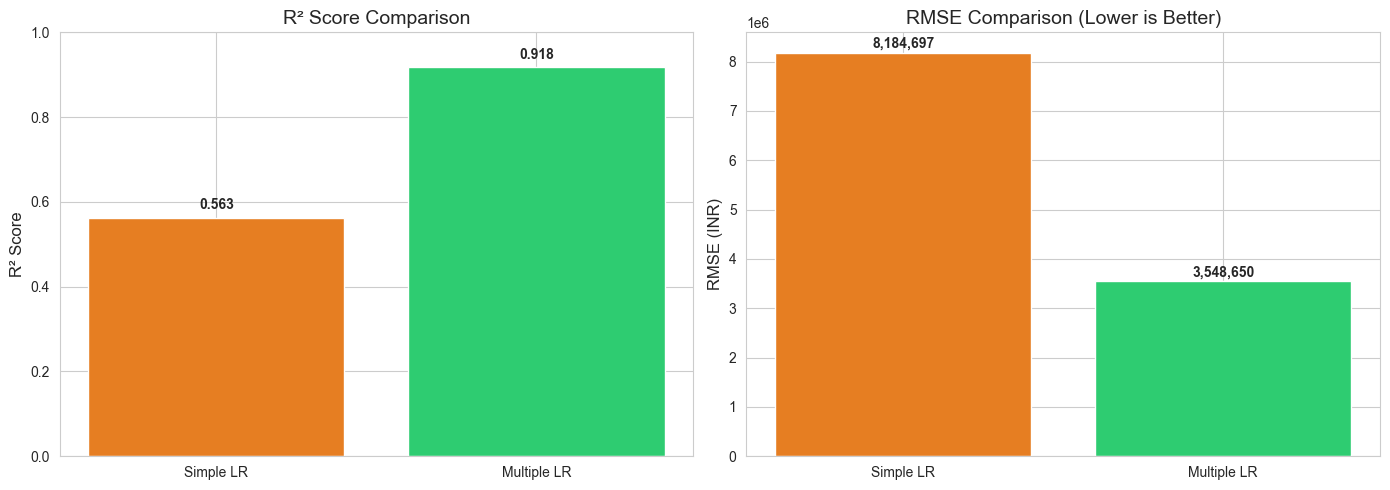

In [34]:
# (b) Metrics ka bar chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models = ["Simple LR", "Multiple LR"]

# R2 comparison
axes[0].bar(models, results_df["R2 Score"], color=["#e67e22", "#2ecc71"])
axes[0].set_title("R² Score Comparison")
axes[0].set_ylabel("R² Score")
axes[0].set_ylim(0, 1)
for i, v in enumerate(results_df["R2 Score"]):
    axes[0].text(i, v + 0.02, f"{v:.3f}", ha="center", fontweight="bold")

# RMSE comparison
axes[1].bar(models, results_df["RMSE"], color=["#e67e22", "#2ecc71"])
axes[1].set_title("RMSE Comparison (Lower is Better)")
axes[1].set_ylabel("RMSE (INR)")
for i, v in enumerate(results_df["RMSE"]):
    axes[1].text(i, v + 100000, f"{v:,.0f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

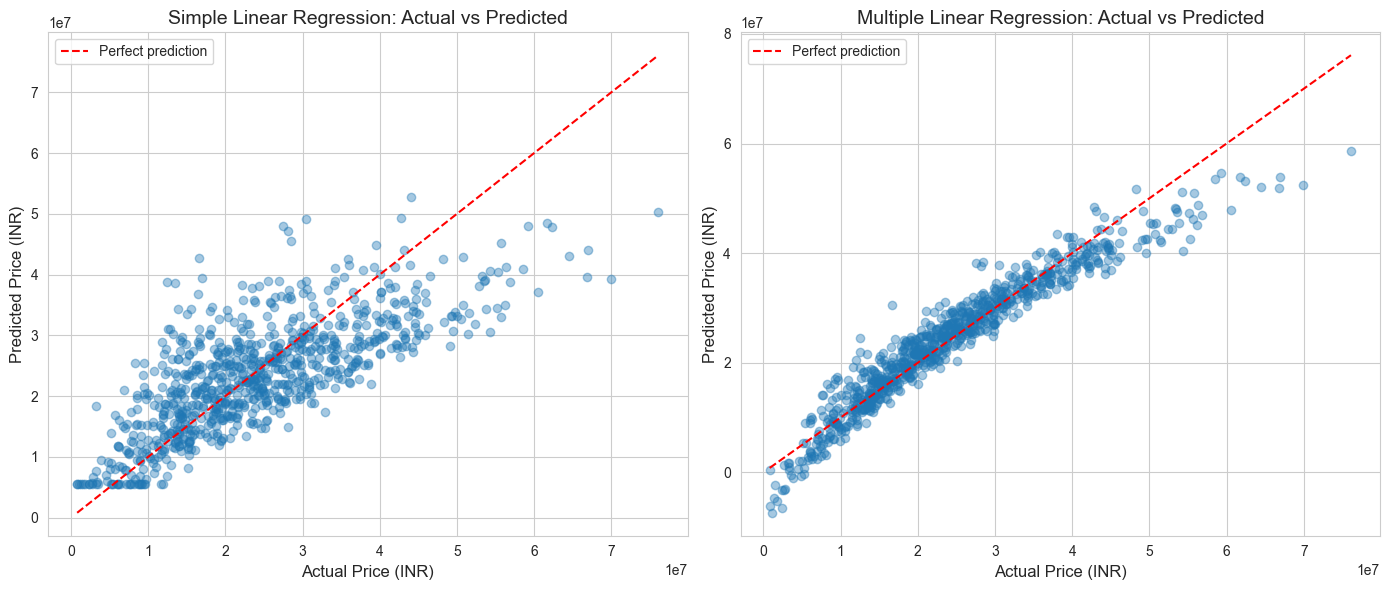

In [35]:
# (c) Actual vs Predicted (dono models side by side)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, pred, title in zip(axes,
                           [y_pred_slr, y_pred_mlr],
                           ["Simple Linear Regression", "Multiple Linear Regression"]):
    ax.scatter(y_test, pred, alpha=0.4)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", label="Perfect prediction")
    ax.set_title(f"{title}: Actual vs Predicted")
    ax.set_xlabel("Actual Price (INR)")
    ax.set_ylabel("Predicted Price (INR)")
    ax.legend()

plt.tight_layout()
plt.show()

**Interpretation (Comparison):**
- **R² improved from 0.563 to 0.918.** The model now explains about 92% of the price variation instead of 56%.
- **RMSE dropped from about ₹81.8 lakh to ₹35.5 lakh** (around 57% lower), and **MAE dropped from about ₹62.9 lakh to ₹26.0 lakh** (around 59% lower).
- **Adjusted R² (0.9168)** is very close to R² (0.9178), which means the extra features are genuinely useful and are not just inflating the score.
- In the Actual vs Predicted plot, the points of Multiple Regression sit **much closer to the red line**, while Simple Regression points are widely scattered.
- **Conclusion:** Multiple Linear Regression is clearly the better model than Simple Linear Regression.

### Task 17: Why Performance Improves

**Why did the performance improve?**

1. **More information:** Simple Regression used only area_sqft. House price also depends on location score, distance from the city, bedrooms, bathrooms, pool, and more. Multiple Regression uses all of them, so it captures more of the real pattern.

2. **Lower bias (less underfitting):** The Simple model was underfitting (R² of only 0.56). Adding features gives the model enough flexibility to learn the relationship better.

3. **Location matters a lot:** location_score and distance_city_km have a strong effect on price (seen in the heatmap), but Simple Regression ignored them. Including them gave the biggest improvement.

4. **No overfitting:** Train R² (0.925) and Test R² (0.918) are very close, so the model generalizes well to new data.

5. **Multicollinearity is under control:** All VIF values are below 10, so correlated features like area, bedrooms, and bathrooms did not harm the model.

**When can performance degrade?** Adding too many irrelevant features can cause overfitting or multicollinearity. In our case this did not happen because the features are relevant and the VIF values are acceptable.

## Part F: Polynomial Regression

### Task 18: Implement Polynomial Regression (Degree 2 and 3)

In [36]:
# Polynomial Regression using Pipeline: Polynomial Features -> Scaling -> Linear Regression
def build_poly_model(degree):
    return Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("lr", LinearRegression())
    ])

# ----- Degree 2 -----
model_poly2 = build_poly_model(2)
model_poly2.fit(X_train, y_train)
y_pred_train_poly2 = model_poly2.predict(X_train)
y_pred_poly2       = model_poly2.predict(X_test)

# ----- Degree 3 -----
model_poly3 = build_poly_model(3)
model_poly3.fit(X_train, y_train)
y_pred_train_poly3 = model_poly3.predict(X_train)
y_pred_poly3       = model_poly3.predict(X_test)

print("✅ Polynomial Regression models trained!")
print("Degree 2 -> number of features:", model_poly2.named_steps["poly"].n_output_features_)
print("Degree 3 -> number of features:", model_poly3.named_steps["poly"].n_output_features_)

✅ Polynomial Regression models trained!
Degree 2 -> number of features: 65
Degree 3 -> number of features: 285


In [37]:
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    pred_te = model.predict(X_te)
    pred_tr = model.predict(X_tr)

    mse  = mean_squared_error(y_te, pred_te)
    mae  = mean_absolute_error(y_te, pred_te)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_te, pred_te)

    n = X_te.shape[0]
    k = model.named_steps["poly"].n_output_features_
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - k - 1)

    return {
        "Model": name, "MSE": mse, "MAE": mae, "RMSE": rmse,
        "R2 Score": r2, "Adjusted R2": adj_r2,
        "Train R2": r2_score(y_tr, pred_tr)
    }

res_poly2 = evaluate_model("Polynomial Regression (Degree 2)", model_poly2, X_train, y_train, X_test, y_test)
res_poly3 = evaluate_model("Polynomial Regression (Degree 3)", model_poly3, X_train, y_train, X_test, y_test)

pd.DataFrame([res_poly2, res_poly3])

,Model,MSE,MAE,RMSE,R2 Score,Adjusted R2,Train R2
0,Polynomial Regression (Degree 2),"5,139,490,891,510.79","1,656,922.80","2,267,044.53",0.97,0.96,0.97
1,Polynomial Regression (Degree 3),"5,413,689,759,326.56","1,707,651.43","2,326,733.71",0.96,0.95,0.97


### Task 19: Compare Linear vs Polynomial Regression (Visually & Numerically)

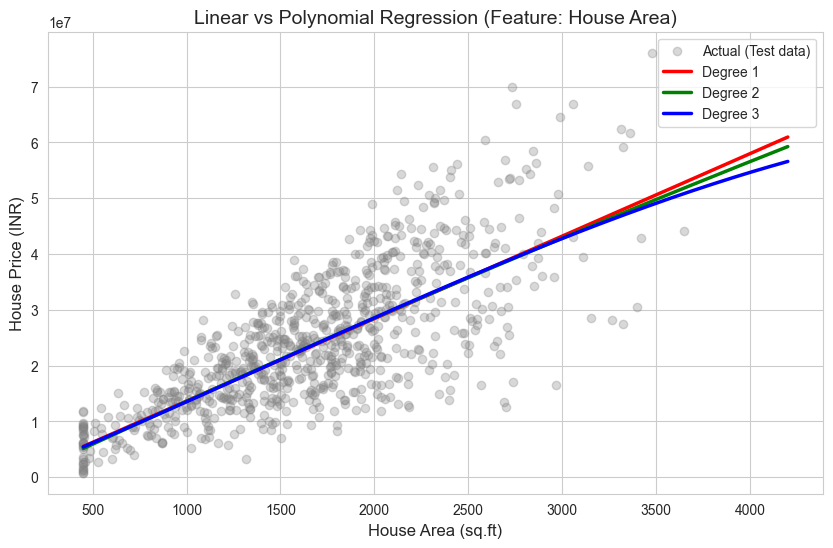

In [38]:
# (a) Visual 1: Curve plot (single feature: area_sqft)
# Fit degree 1, 2, 3 on area_sqft only (for visualization)
area_train = X_train[["area_sqft"]]
area_test  = X_test[["area_sqft"]]
area_range = pd.DataFrame({"area_sqft": np.linspace(area_train["area_sqft"].min(),
                                                    area_train["area_sqft"].max(), 300)})

plt.figure(figsize=(10, 6))
plt.scatter(area_test, y_test, alpha=0.3, color="gray", label="Actual (Test data)")

colors = {1: "red", 2: "green", 3: "blue"}
for degree in [1, 2, 3]:
    m = Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("lr", LinearRegression())
    ]).fit(area_train, y_train)
    plt.plot(area_range, m.predict(area_range), color=colors[degree], linewidth=2.5,
             label=f"Degree {degree}")

plt.title("Linear vs Polynomial Regression (Feature: House Area)")
plt.xlabel("House Area (sq.ft)")
plt.ylabel("House Price (INR)")
plt.legend()
plt.show()

**Interpretation:**
- The red (linear), green (degree 2) and blue (degree 3) lines almost **overlap** each other. The curves are only very slightly bent.
- This shows that the relationship between area and price is already **almost linear**, so adding polynomial terms for area alone gives **almost no improvement**.
- The big scatter of points around the lines shows that area alone cannot explain the price. The error is high because other features (location, bedrooms, etc.) are missing, not because the line shape is wrong.

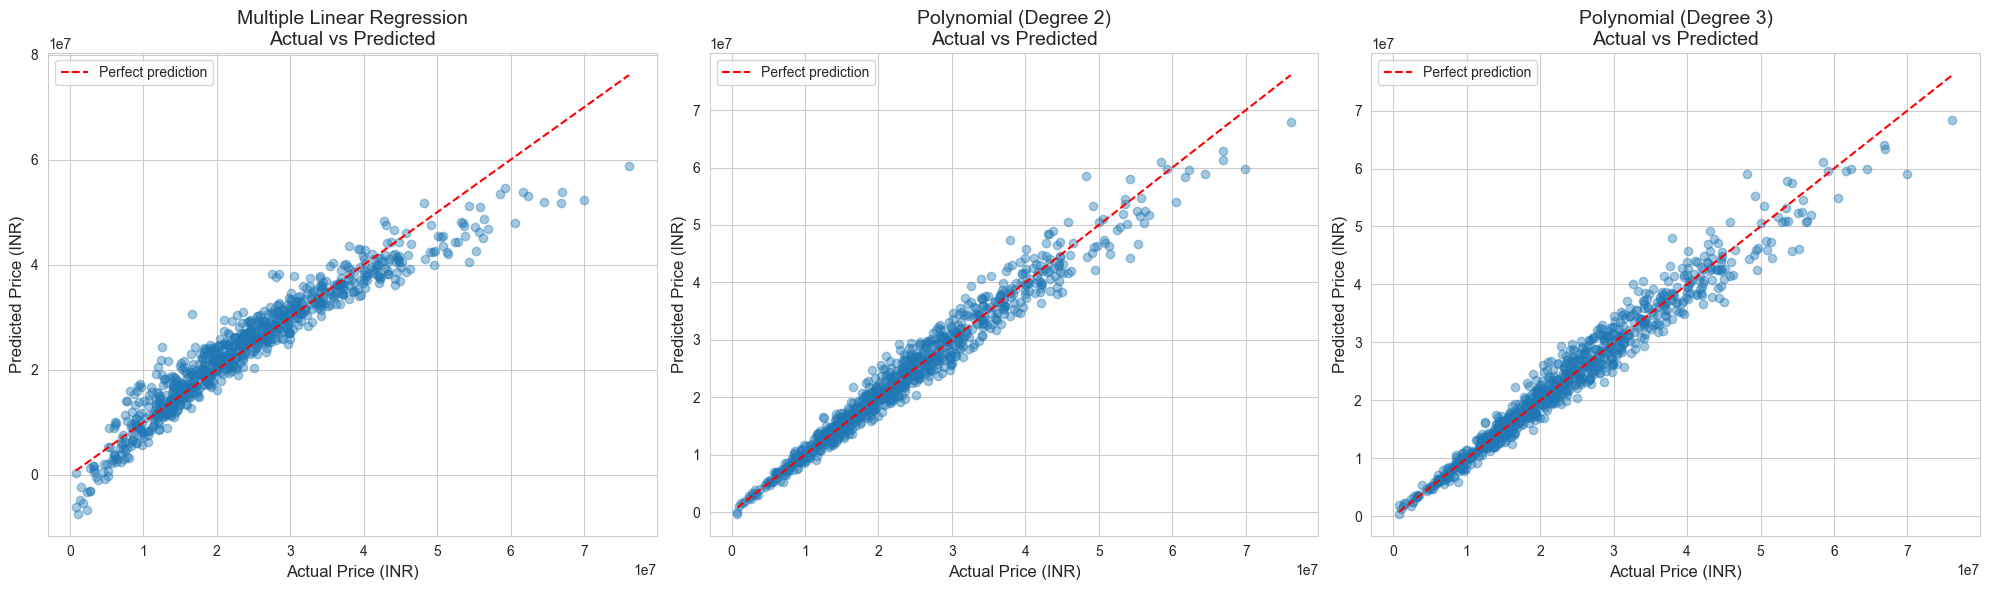

In [39]:
# (b) Visual 2: Actual vs Predicted (3 models)
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, pred, title in zip(axes,
                           [y_pred_mlr, y_pred_poly2, y_pred_poly3],
                           ["Multiple Linear Regression", "Polynomial (Degree 2)", "Polynomial (Degree 3)"]):
    ax.scatter(y_test, pred, alpha=0.4)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", label="Perfect prediction")
    ax.set_title(f"{title}\nActual vs Predicted")
    ax.set_xlabel("Actual Price (INR)")
    ax.set_ylabel("Predicted Price (INR)")
    ax.legend()

plt.tight_layout()
plt.show()

In [40]:
# (c) Numerical comparison table (saare models)
results_df = pd.concat([results_df, pd.DataFrame([res_poly2, res_poly3]).drop(columns="Train R2")],
                       ignore_index=True)
results_df

,Model,MSE,MAE,RMSE,R2 Score,Adjusted R2
0,Simple Linear Regression,"66,989,260,021,849.47","6,294,593.70","8,184,696.70",0.56,0.56
1,Multiple Linear Regression,"12,592,918,884,127.74","2,604,991.41","3,548,650.29",0.92,0.92
2,Polynomial Regression (Degree 2),"5,139,490,891,510.79","1,656,922.80","2,267,044.53",0.97,0.96
3,Polynomial Regression (Degree 3),"5,413,689,759,326.56","1,707,651.43","2,326,733.71",0.96,0.95


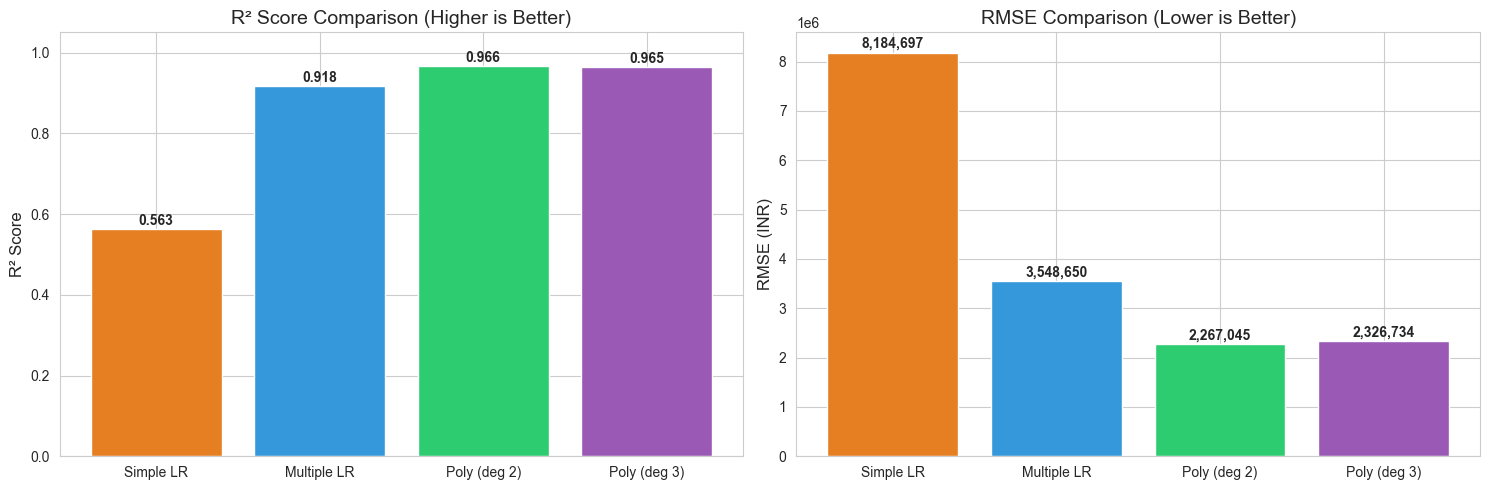

In [41]:
# (d) Bar chart
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
short_names = ["Simple LR", "Multiple LR", "Poly (deg 2)", "Poly (deg 3)"]
bar_colors = ["#e67e22", "#3498db", "#2ecc71", "#9b59b6"]

axes[0].bar(short_names, results_df["R2 Score"], color=bar_colors)
axes[0].set_title("R² Score Comparison (Higher is Better)")
axes[0].set_ylabel("R² Score")
axes[0].set_ylim(0, 1.05)
for i, v in enumerate(results_df["R2 Score"]):
    axes[0].text(i, v + 0.01, f"{v:.3f}", ha="center", fontweight="bold")

axes[1].bar(short_names, results_df["RMSE"], color=bar_colors)
axes[1].set_title("RMSE Comparison (Lower is Better)")
axes[1].set_ylabel("RMSE (INR)")
for i, v in enumerate(results_df["RMSE"]):
    axes[1].text(i, v + 100000, f"{v:,.0f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

**Interpretation (Comparison):**
- **Polynomial (Degree 2) is the best model so far.** Test R² improved from 0.918 (Multiple LR) to about 0.966, and RMSE dropped from about ₹35.5 lakh to about ₹22.7 lakh.
- **Degree 3 is slightly worse than Degree 2** on test data (R² 0.9646 vs 0.9664, RMSE ₹23.3 lakh vs ₹22.7 lakh), even though it is more complex.
- **Adjusted R² falls more for Degree 3 (0.9465 vs 0.9636)** because it uses 285 features. This means many of the extra features are not useful.
- In the Actual vs Predicted plots, the Polynomial models stay closer to the red line, especially for expensive houses, where Multiple LR was weaker.
- **Conclusion:** Some features have a non-linear effect on price (or interact with each other, such as area × location). Degree 2 captures this well. Going to Degree 3 does not help.

### Task 20: Identify Signs of Overfitting / Underfitting

In [42]:
degrees = [1, 2, 3, 4]
train_scores, test_scores, test_rmse = [], [], []

for d in degrees:
    m = build_poly_model(d)
    m.fit(X_train, y_train)
    train_scores.append(r2_score(y_train, m.predict(X_train)))
    test_scores.append(r2_score(y_test, m.predict(X_test)))
    test_rmse.append(np.sqrt(mean_squared_error(y_test, m.predict(X_test))))

degree_df = pd.DataFrame({
    "Degree": degrees,
    "Train R2": train_scores,
    "Test R2": test_scores,
    "Gap (Train - Test)": np.array(train_scores) - np.array(test_scores),
    "Test RMSE": test_rmse
})
degree_df

,Degree,Train R2,Test R2,Gap (Train - Test),Test RMSE
0,1,0.92,0.92,0.01,"3,548,650.29"
1,2,0.97,0.97,0.00,"2,267,044.53"
2,3,0.97,0.96,0.01,"2,326,733.71"
3,4,0.98,0.93,0.05,"3,341,702.68"


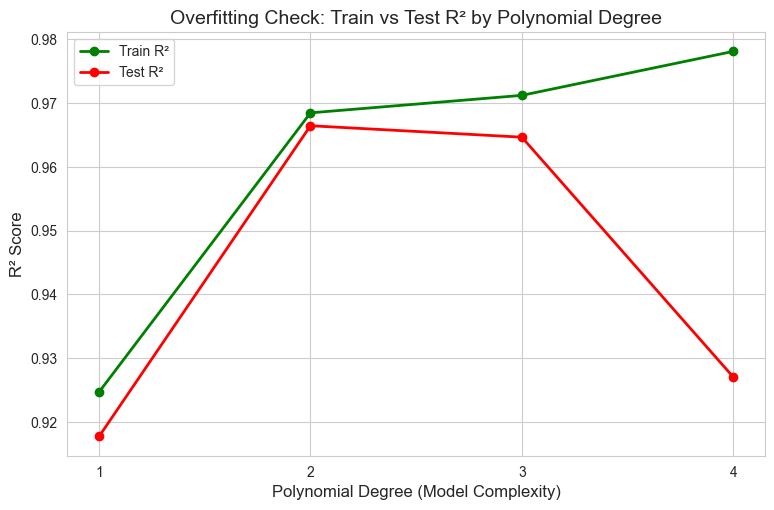

In [43]:
# Train vs Test R2 across model complexity
plt.figure(figsize=(9, 5.5))
plt.plot(degrees, train_scores, marker="o", linewidth=2, label="Train R²", color="green")
plt.plot(degrees, test_scores, marker="o", linewidth=2, label="Test R²", color="red")
plt.xticks(degrees)
plt.title("Overfitting Check: Train vs Test R² by Polynomial Degree")
plt.xlabel("Polynomial Degree (Model Complexity)")
plt.ylabel("R² Score")
plt.legend()
plt.grid(True)
plt.show()

**Interpretation (Overfitting / Underfitting):**
- **Underfitting:** The Simple Linear Regression model (one feature) had Train R² ≈ 0.572 and Test R² ≈ 0.563. Both scores are low, so the model is **underfitting** (high bias). Degree 1 with all features (R² ≈ 0.92) is also a little underfit compared with Degree 2.
- **Good fit:** **Degree 2** has the highest test score (0.966) and a very small gap between train and test (about 0.002). This is the best balance.
- **Start of overfitting:** At **Degree 3**, train R² goes up (0.971) but test R² goes down (0.965). The gap grows, which is the first sign of overfitting.
- **Clear overfitting:** At **Degree 4** (1000 features), train R² is 0.978 but test R² falls sharply to 0.927 and test RMSE rises. The model is memorizing the training data instead of learning the general pattern.
- **Rule used:** Overfitting = high train score + clearly lower test score. Underfitting = low score on both train and test.
- **Conclusion:** Degree 2 is the best choice. Higher degrees add complexity without better test performance.

## Part G: Gradient Descent Optimization

### Task 21: Gradient Descent (Concept)

**What is Gradient Descent?**
Gradient Descent is an optimization algorithm that finds the best model weights by reducing the error step by step. Think of walking down a hill in fog: at every step you look at the slope under your feet and move downhill, until you reach the bottom (minimum error).

**Steps:**
1. Start with random (or zero) weights.
2. Make predictions and calculate the loss (MSE).
3. Calculate the **gradient** (the slope of the loss for each weight).
4. Update the weights in the opposite direction of the gradient:

   `w = w - α × gradient`   (α = learning rate)

5. Repeat until the loss stops decreasing (**convergence**).

**For Linear Regression (MSE loss):**
`Loss = (1/n) Σ (ŷ - y)²`  and  `gradient = (2/n) Xᵀ (Xw - y)`

**Learning rate (α):** If too small, learning is slow. If too large, the loss jumps around and may never converge.

**Three types:**
| Type | Data used per update | Behaviour |
|---|---|---|
| Batch GD | All training samples | Smooth and stable, but each update is expensive |
| Stochastic GD (SGD) | 1 sample | Very fast updates, but noisy path |
| Mini-Batch GD | Small group (e.g. 32 samples) | Balance of speed and stability |

In [44]:
# Scale features (fit only on training data)
scaler_gd = StandardScaler()
X_train_gd = scaler_gd.fit_transform(X_train)
X_test_gd  = scaler_gd.transform(X_test)

# Scale target (we convert predictions back to INR later)
y_mean, y_std = y_train.mean(), y_train.std()
y_train_gd = ((y_train - y_mean) / y_std).values

# Add a column of 1s for the intercept (bias)
X_train_b = np.c_[np.ones(X_train_gd.shape[0]), X_train_gd]
X_test_b  = np.c_[np.ones(X_test_gd.shape[0]), X_test_gd]

print("X_train_b shape:", X_train_b.shape)   # (3360, 11)

# ---------- Helper functions ----------
def compute_loss(X, y, w):
    """Mean Squared Error"""
    return np.mean((X @ w - y) ** 2)

def evaluate_gd(name, w, losses, train_time):
    """Convert predictions back to INR and calculate metrics"""
    pred_test  = (X_test_b  @ w) * y_std + y_mean
    pred_train = (X_train_b @ w) * y_std + y_mean
    mse = mean_squared_error(y_test, pred_test)
    return {
        "Method": name,
        "MSE": mse,
        "MAE": mean_absolute_error(y_test, pred_test),
        "RMSE": np.sqrt(mse),
        "R2 Score": r2_score(y_test, pred_test),
        "Train R2": r2_score(y_train, pred_train),
        "Final Loss": losses[-1],
        "Train Time (sec)": train_time
    }

def plot_loss(losses, title, color):
    plt.figure(figsize=(8, 5))
    plt.plot(range(1, len(losses) + 1), losses, color=color, linewidth=2)
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("Training Loss (MSE, scaled)")
    plt.grid(True)
    plt.show()

# Best possible loss (from closed-form Multiple Linear Regression of Part E)
pred_best = (model_mlr.predict(X_train) - y_mean) / y_std
min_loss = np.mean((pred_best - y_train_gd) ** 2)
print(f"Minimum possible loss (Linear Regression solution): {min_loss:.5f}")

X_train_b shape: (3360, 11)
Minimum possible loss (Linear Regression solution): 0.07526


### Task 22: Implement Batch Gradient Descent

✅ Batch Gradient Descent finished!
Final loss: 0.07526 | Time: 0.0449 sec


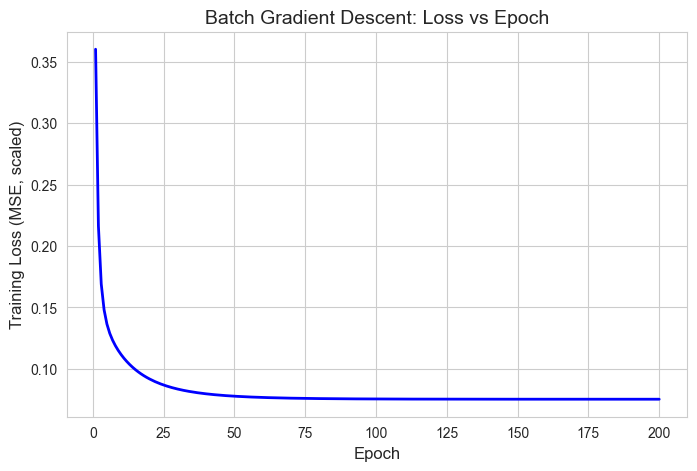

In [45]:
def batch_gradient_descent(X, y, lr=0.1, epochs=200):
    n = X.shape[0]
    w = np.zeros(X.shape[1])          # start with zero weights
    losses = []

    start = time.time()
    for epoch in range(epochs):
        gradient = (2 / n) * X.T @ (X @ w - y)    # gradient using ALL samples
        w = w - lr * gradient                       # update weights
        losses.append(compute_loss(X, y, w))
    train_time = time.time() - start

    return w, losses, train_time

w_batch, losses_batch, time_batch = batch_gradient_descent(X_train_b, y_train_gd, lr=0.1, epochs=200)

print("✅ Batch Gradient Descent finished!")
print(f"Final loss: {losses_batch[-1]:.5f} | Time: {time_batch:.4f} sec")
plot_loss(losses_batch, "Batch Gradient Descent: Loss vs Epoch", "blue")

**Interpretation:**
- The loss falls quickly in the first few epochs (from about 0.36) and then slowly flattens, giving a **smooth curve** with no noise.
- It reaches the minimum possible loss (about 0.0753) after around 100 to 200 epochs, which means Batch GD has **converged** to the same solution as the normal Linear Regression.
- One update uses all 3360 samples, so each step is accurate, but many epochs are needed here.

### Task 23: Implement Stochastic Gradient Descent (SGD)

✅ Stochastic Gradient Descent finished!
Final loss: 0.07614 | Time: 0.9455 sec


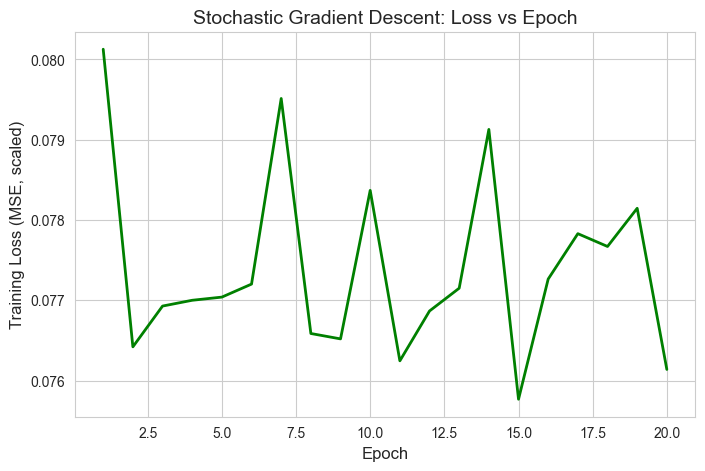

In [46]:
def stochastic_gradient_descent(X, y, lr=0.002, epochs=20):
    rng = np.random.default_rng(RANDOM_STATE)
    n = X.shape[0]
    w = np.zeros(X.shape[1])
    losses = []

    start = time.time()
    for epoch in range(epochs):
        for i in rng.permutation(n):                    # shuffle samples every epoch
            xi, yi = X[i], y[i]
            gradient = 2 * xi * (xi @ w - yi)           # gradient from ONE sample
            w = w - lr * gradient                       # update after every sample
        losses.append(compute_loss(X, y, w))
    train_time = time.time() - start

    return w, losses, train_time

w_sgd, losses_sgd, time_sgd = stochastic_gradient_descent(X_train_b, y_train_gd, lr=0.002, epochs=20)

print("✅ Stochastic Gradient Descent finished!")
print(f"Final loss: {losses_sgd[-1]:.5f} | Time: {time_sgd:.4f} sec")
plot_loss(losses_sgd, "Stochastic Gradient Descent: Loss vs Epoch", "green")

**Interpretation:**
- SGD reaches a low loss (about 0.080) already after the **first epoch**, because it makes 3360 weight updates per epoch.
- The curve is **slightly noisy** (small ups and downs) because each update uses only one sample, so the direction is not perfectly accurate.
- It settles near the minimum (about 0.076) but keeps wobbling around it instead of stopping exactly at 0.0753.

### Task 24: Implement Mini-Batch Gradient Descent

✅ Mini-Batch Gradient Descent finished!
Final loss: 0.07569 | Time: 0.1651 sec


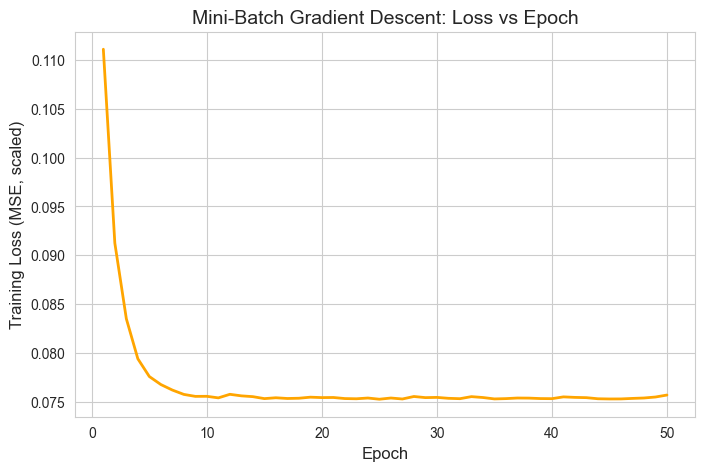

In [47]:
def mini_batch_gradient_descent(X, y, lr=0.01, epochs=50, batch_size=32):
    rng = np.random.default_rng(RANDOM_STATE)
    n = X.shape[0]
    w = np.zeros(X.shape[1])
    losses = []

    start = time.time()
    for epoch in range(epochs):
        indices = rng.permutation(n)
        for s in range(0, n, batch_size):
            batch = indices[s:s + batch_size]
            Xb, yb = X[batch], y[batch]
            gradient = (2 / len(batch)) * Xb.T @ (Xb @ w - yb)   # gradient from a small batch
            w = w - lr * gradient
        losses.append(compute_loss(X, y, w))
    train_time = time.time() - start

    return w, losses, train_time

w_mini, losses_mini, time_mini = mini_batch_gradient_descent(X_train_b, y_train_gd, lr=0.01, epochs=50, batch_size=32)

print("✅ Mini-Batch Gradient Descent finished!")
print(f"Final loss: {losses_mini[-1]:.5f} | Time: {time_mini:.4f} sec")
plot_loss(losses_mini, "Mini-Batch Gradient Descent: Loss vs Epoch", "orange")

**Interpretation:**
- Mini-Batch GD (batch size = 32) starts at a higher loss than SGD (about 0.11 after epoch 1) but falls **quickly and smoothly** to about 0.0757 within a few epochs.
- The curve is **less noisy than SGD** and faster than Batch GD, because it averages the gradient over 32 samples.
- It ends very close to the minimum loss (0.0753).

### Task 25: Compare Convergence Behaviour and Training Time

In [48]:
# (a) Numerical comparison table
gd_results = pd.DataFrame([
    evaluate_gd("Batch GD",      w_batch, losses_batch, time_batch),
    evaluate_gd("SGD",           w_sgd,   losses_sgd,   time_sgd),
    evaluate_gd("Mini-Batch GD", w_mini,  losses_mini,  time_mini)
])

# Number of epochs needed to get close to the minimum loss (within 3%)
threshold = min_loss * 1.03
gd_results["Epochs to Converge"] = [
    next((i + 1 for i, v in enumerate(l) if v < threshold), "Not reached")
    for l in [losses_batch, losses_sgd, losses_mini]
]

# Add the closed-form Linear Regression (Part E) for reference
print(f"Reference -> Multiple Linear Regression R²: {r2_mlr:.4f}")
gd_results

Reference -> Multiple Linear Regression R²: 0.9178


,Method,MSE,MAE,RMSE,R2 Score,Train R2,Final Loss,Train Time (sec),Epochs to Converge
0,Batch GD,"12,596,494,762,318.88","2,605,250.91","3,549,154.09",0.92,0.92,0.08,0.04,52
1,SGD,"12,930,922,497,726.71","2,617,150.70","3,595,959.19",0.92,0.92,0.08,0.95,2
2,Mini-Batch GD,"12,823,344,060,331.11","2,620,447.92","3,580,969.71",0.92,0.92,0.08,0.17,6


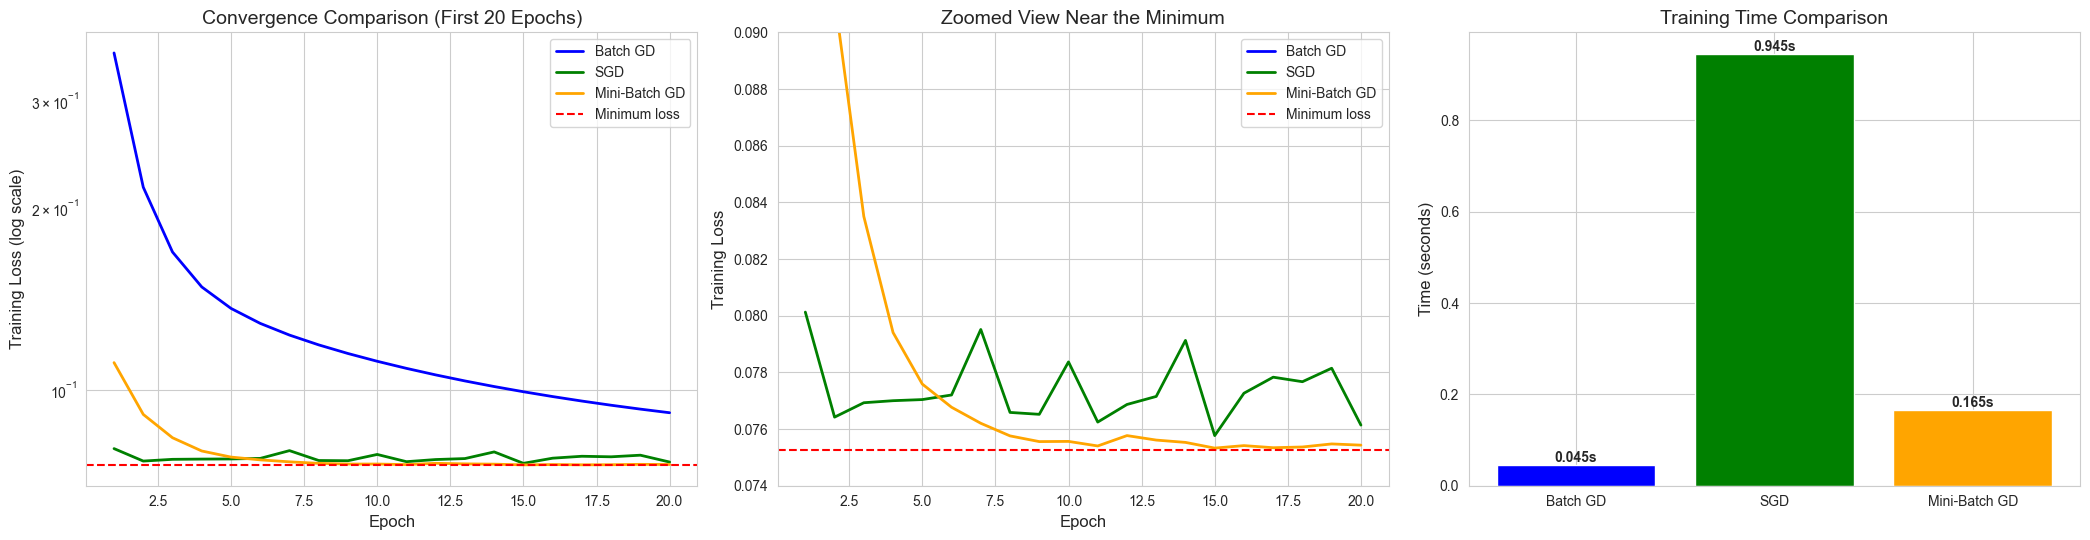

In [49]:
# (b) Convergence + time graphs
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))

# Panel 1: loss curves for the first 20 epochs (log scale)
for losses, label, color in [(losses_batch, "Batch GD", "blue"),
                             (losses_sgd, "SGD", "green"),
                             (losses_mini, "Mini-Batch GD", "orange")]:
    axes[0].plot(range(1, 21), losses[:20], label=label, color=color, linewidth=2)
axes[0].axhline(min_loss, color="red", linestyle="--", label="Minimum loss")
axes[0].set_yscale("log")
axes[0].set_title("Convergence Comparison (First 20 Epochs)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training Loss (log scale)")
axes[0].legend()

# Panel 2: zoom near the minimum to see noise
for losses, label, color in [(losses_batch, "Batch GD", "blue"),
                             (losses_sgd, "SGD", "green"),
                             (losses_mini, "Mini-Batch GD", "orange")]:
    axes[1].plot(range(1, 21), losses[:20], label=label, color=color, linewidth=2)
axes[1].axhline(min_loss, color="red", linestyle="--", label="Minimum loss")
axes[1].set_ylim(0.074, 0.09)
axes[1].set_title("Zoomed View Near the Minimum")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Training Loss")
axes[1].legend()

# Panel 3: training time
axes[2].bar(gd_results["Method"], gd_results["Train Time (sec)"], color=["blue", "green", "orange"])
axes[2].set_title("Training Time Comparison")
axes[2].set_ylabel("Time (seconds)")
for i, v in enumerate(gd_results["Train Time (sec)"]):
    axes[2].text(i, v, f"{v:.3f}s", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()

**Interpretation (Comparison):**

**Convergence behaviour**
- **Batch GD:** Smooth and stable, with no noise. It is the slowest in terms of epochs (about 50 epochs to get close to the minimum), but it ends exactly at the best solution (loss 0.07526, R² 0.9177, same as Linear Regression).
- **SGD:** Fastest in epochs (close to the minimum within 2 epochs), but the curve is **noisy** and it never settles perfectly. Its final R² (0.9156) is slightly lower.
- **Mini-Batch GD:** Reaches the minimum in about 6 epochs with a **much smoother curve than SGD**. Its R² (0.9163) is very close to Batch GD.

**Training time**
- Per epoch, **SGD is the slowest** because it makes 3360 separate updates in a Python loop. Mini-Batch makes about 105 updates per epoch, and Batch GD makes only 1.
- In total time, Batch GD looks fastest here only because the dataset is small (3360 rows) and its matrix operations are vectorized by NumPy. On very large datasets, one Batch GD step becomes very expensive, and Mini-Batch or SGD are preferred.

**Accuracy**
- All three methods give almost the same model quality (test R² between 0.9156 and 0.9177) and match the closed-form Multiple Linear Regression, so Gradient Descent is working correctly.

**Impact of Gradient Descent optimization:** Gradient Descent finds the same solution as the formula-based method, but it also works for large data and for models that have no closed-form solution.

**Conclusion:** Mini-Batch GD gives the best balance of speed, stability, and accuracy, which is why it is the most used method in practice.

## Part H: Bias-Variance & Model Diagnostics

### Task 26: Analyze Bias and Variance (Simple vs Multiple vs Polynomial)

**How we measure Bias and Variance:**
- **Train vs Test error:** A model with high error on both is high-bias (underfitting). A model with low train error but high test error is high-variance (overfitting).
- **Cross-validation (5-fold):** If the score changes a lot between folds, the model is unstable (high variance).
- **Bootstrap estimate:** We train each model on 50 random re-samples of the training data and look at the test predictions.
  - **Bias²** = how far the *average* prediction is from the actual price.
  - **Variance** = how much predictions *change* when the training data changes.
- **Note:** The true price function is unknown, so the Bias² here also contains the unavoidable noise in the data. Still, it is fine for comparing models with each other.

In [50]:
from sklearn.model_selection import KFold

all_features = list(X_train.columns)

# (features used, polynomial degree)
model_configs = {
    "Simple LR":    (["area_sqft"], 1),
    "Multiple LR":  (all_features, 1),
    "Poly (deg 2)": (all_features, 2),
    "Poly (deg 3)": (all_features, 3),
    "Poly (deg 4)": (all_features, 4),     # extra model, used in Task 27
}

def estimate_bias_variance(degree, cols, n_boot=50):
    """Estimate Bias² and Variance using bootstrap re-sampling"""
    rng = np.random.default_rng(RANDOM_STATE)
    n = len(X_train)
    all_preds = np.zeros((n_boot, len(X_test)))

    for b in range(n_boot):
        idx = rng.choice(n, n, replace=True)                  # random sample with replacement
        m = build_poly_model(degree)
        m.fit(X_train.iloc[idx][cols], y_train.iloc[idx])
        all_preds[b] = m.predict(X_test[cols])

    mean_pred = all_preds.mean(axis=0)
    bias_sq  = np.mean((mean_pred - y_test.values) ** 2)
    variance = np.mean(all_preds.var(axis=0))
    return bias_sq, variance

kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []

for name, (cols, degree) in model_configs.items():
    model = build_poly_model(degree).fit(X_train[cols], y_train)
    pred_tr = model.predict(X_train[cols])
    pred_te = model.predict(X_test[cols])

    cv_scores = cross_val_score(build_poly_model(degree), X_train[cols], y_train,
                                cv=kfold, scoring="r2")
    bias_sq, variance = estimate_bias_variance(degree, cols)

    rows.append({
        "Model": name,
        "Train RMSE (lakh)": np.sqrt(mean_squared_error(y_train, pred_tr)) / 1e5,
        "Test RMSE (lakh)":  np.sqrt(mean_squared_error(y_test, pred_te)) / 1e5,
        "Train R2": r2_score(y_train, pred_tr),
        "Test R2":  r2_score(y_test, pred_te),
        "CV R2 Mean": cv_scores.mean(),
        "CV R2 Std":  cv_scores.std(),
        "Bias² (x1e12)":    bias_sq / 1e12,
        "Variance (x1e12)": variance / 1e12,
        "Total Error (x1e12)": (bias_sq + variance) / 1e12
    })

diagnostics_df = pd.DataFrame(rows)
print("✅ Diagnostics calculated!")
diagnostics_df.iloc[:4]     # Task 26 shows the first 4 models

✅ Diagnostics calculated!


,Model,Train RMSE (lakh),Test RMSE (lakh),Train R2,Test R2,CV R2 Mean,CV R2 Std,Bias² (x1e12),Variance (x1e12),Total Error (x1e12)
0,Simple LR,81.04,81.85,0.57,0.56,0.57,0.01,66.94,0.04,66.98
1,Multiple LR,34.00,35.49,0.92,0.92,0.92,0.01,12.60,0.04,12.64
2,Poly (deg 2),22.01,22.67,0.97,0.97,0.97,0.00,5.13,0.11,5.25
3,Poly (deg 3),21.03,23.27,0.97,0.96,0.96,0.00,5.38,0.59,5.98


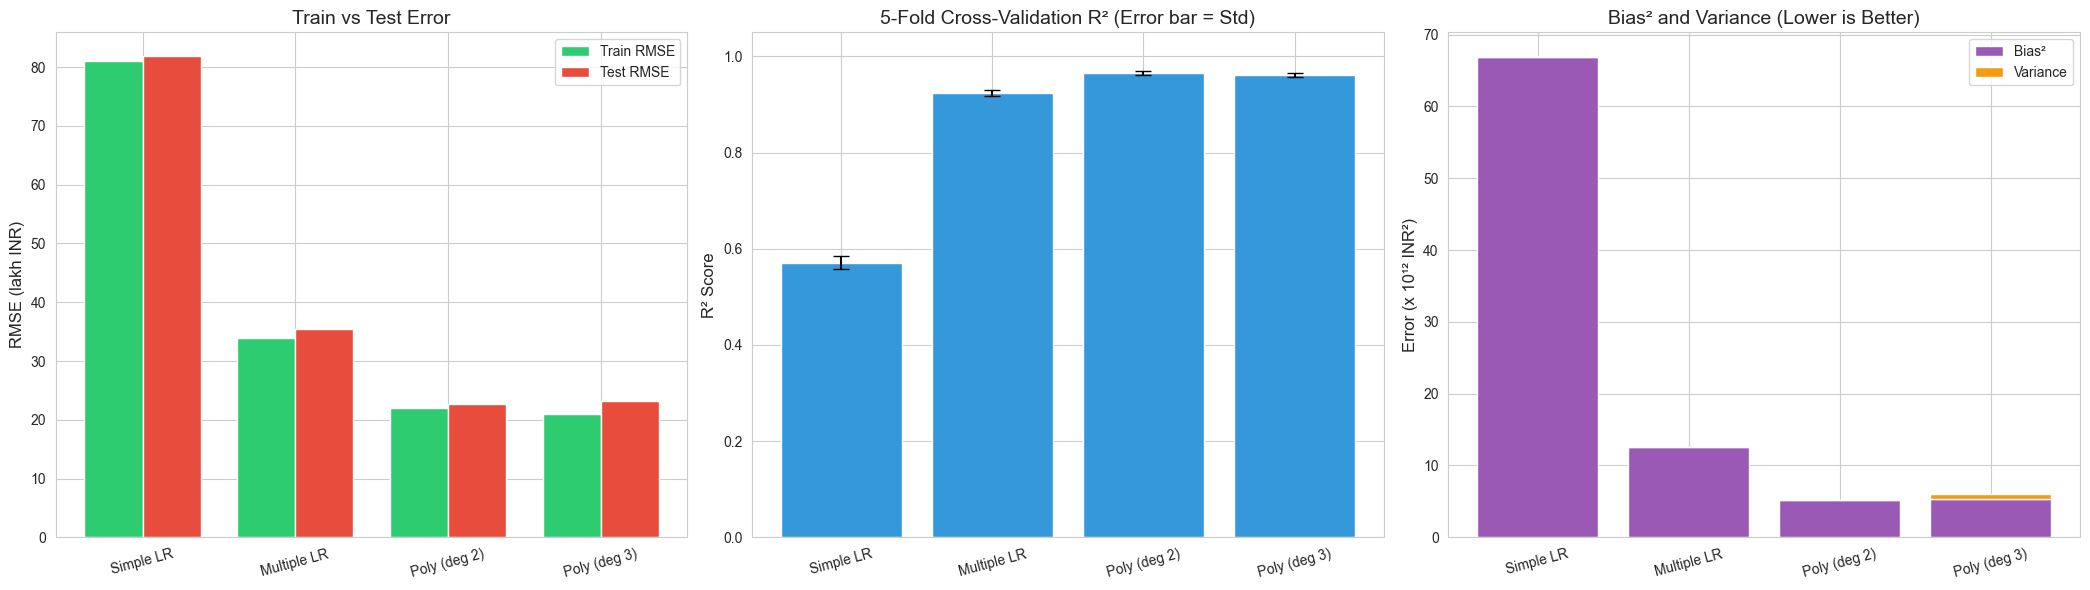

In [51]:
plot_df = diagnostics_df.iloc[:4]
names = plot_df["Model"]
x = np.arange(len(names))

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# Graph 1: Train vs Test RMSE
w = 0.38
axes[0].bar(x - w/2, plot_df["Train RMSE (lakh)"], w, label="Train RMSE", color="#2ecc71")
axes[0].bar(x + w/2, plot_df["Test RMSE (lakh)"],  w, label="Test RMSE",  color="#e74c3c")
axes[0].set_xticks(x); axes[0].set_xticklabels(names, rotation=15)
axes[0].set_title("Train vs Test Error")
axes[0].set_ylabel("RMSE (lakh INR)")
axes[0].legend()

# Graph 2: Cross-validation R2 with error bars
axes[1].bar(names, plot_df["CV R2 Mean"], yerr=plot_df["CV R2 Std"], capsize=6, color="#3498db")
axes[1].set_title("5-Fold Cross-Validation R² (Error bar = Std)")
axes[1].set_ylabel("R² Score")
axes[1].set_ylim(0, 1.05)
axes[1].tick_params(axis="x", rotation=15)

# Graph 3: Bias² and Variance (stacked)
axes[2].bar(names, plot_df["Bias² (x1e12)"], label="Bias²", color="#9b59b6")
axes[2].bar(names, plot_df["Variance (x1e12)"], bottom=plot_df["Bias² (x1e12)"],
            label="Variance", color="#f39c12")
axes[2].set_title("Bias² and Variance (Lower is Better)")
axes[2].set_ylabel("Error (x 10¹² INR²)")
axes[2].tick_params(axis="x", rotation=15)
axes[2].legend()

plt.tight_layout()
plt.show()

**Interpretation (Bias and Variance):**

- **Simple Linear Regression: HIGH BIAS, LOW VARIANCE (Underfitting).** Train RMSE (81.0 lakh) and Test RMSE (81.8 lakh) are both high and almost equal. Its Bias² (66.9) is by far the largest, while the variance is tiny (0.04). One feature is too simple to learn the price pattern.

- **Multiple Linear Regression: MEDIUM BIAS, LOW VARIANCE.** Bias² drops to 12.6 because more features are used, and variance stays very small (0.04). Train and test RMSE are close (34.0 and 35.5 lakh), so there is no overfitting. It is still a bit too simple, because it cannot capture non-linear effects.

- **Polynomial Regression (Degree 2): LOW BIAS, LOW VARIANCE.** Bias² falls to 5.13 (the lowest) and variance is still small (0.11). Train and test errors are almost the same (22.0 and 22.7 lakh) and the cross-validation score is stable (0.966 ± 0.004).

- **Polynomial Regression (Degree 3): LOW BIAS, HIGHER VARIANCE.** Bias² does not improve (5.38), but variance rises to about 5 times that of Degree 2 (0.59 vs 0.11). The gap between train (21.0) and test (23.3) widens, which is an early sign of overfitting.

- **Overall:** Moving from Simple to Multiple to Polynomial (degree 2) reduces bias a lot. Moving to degree 3 only increases variance without reducing bias further.

### Task 27: Effect of Model Complexity on Prediction Error

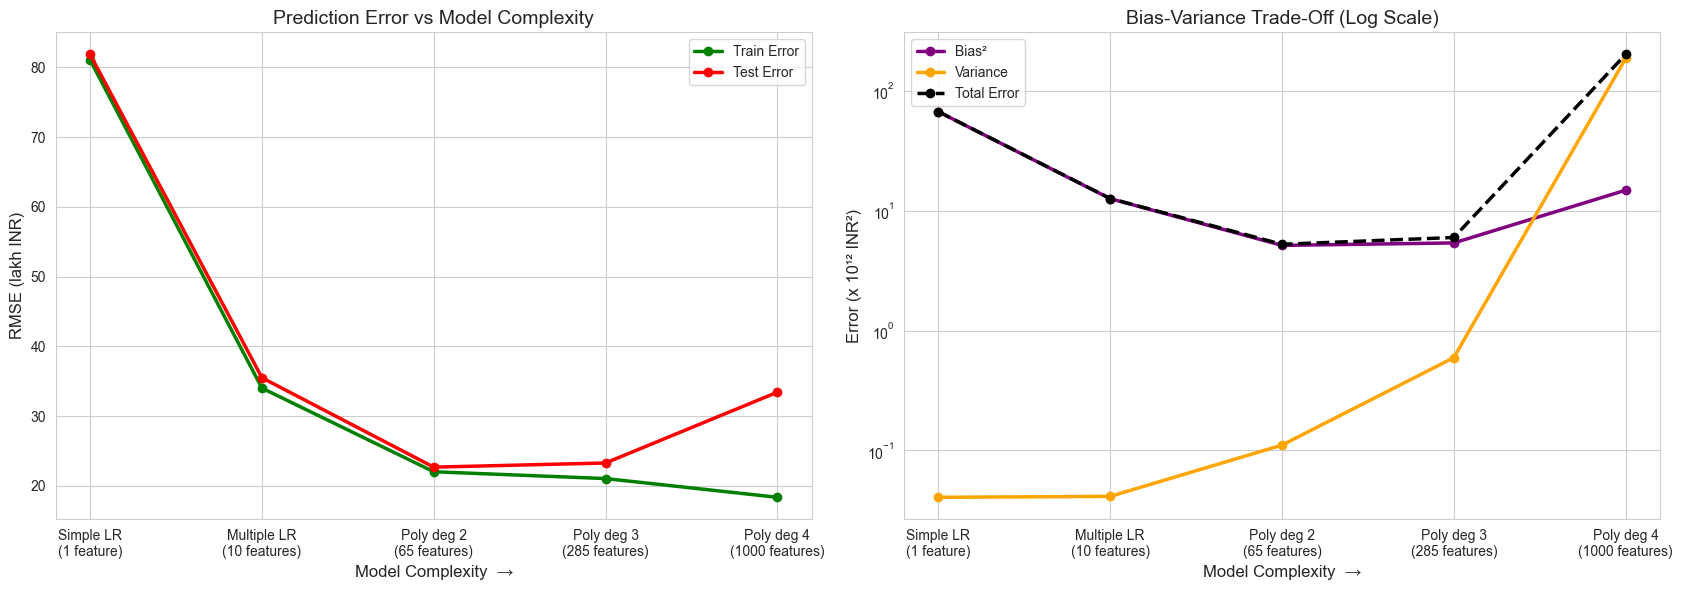

,Model,Train RMSE (lakh),Test RMSE (lakh),CV R2 Mean,CV R2 Std,Bias² (x1e12),Variance (x1e12),Total Error (x1e12)
0,Simple LR,81.04,81.85,0.57,0.01,66.94,0.04,66.98
1,Multiple LR,34.00,35.49,0.92,0.01,12.60,0.04,12.64
2,Poly (deg 2),22.01,22.67,0.97,0.00,5.13,0.11,5.25
3,Poly (deg 3),21.03,23.27,0.96,0.00,5.38,0.59,5.98
4,Poly (deg 4),18.35,33.42,0.85,0.04,14.81,186.12,200.93


In [52]:
complexity_labels = ["Simple LR\n(1 feature)", "Multiple LR\n(10 features)",
                     "Poly deg 2\n(65 features)", "Poly deg 3\n(285 features)",
                     "Poly deg 4\n(1000 features)"]
x = np.arange(len(complexity_labels))

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# Graph 1: Train vs Test error as complexity increases
axes[0].plot(x, diagnostics_df["Train RMSE (lakh)"], marker="o", linewidth=2.5, color="green", label="Train Error")
axes[0].plot(x, diagnostics_df["Test RMSE (lakh)"],  marker="o", linewidth=2.5, color="red",   label="Test Error")
axes[0].set_xticks(x); axes[0].set_xticklabels(complexity_labels)
axes[0].set_title("Prediction Error vs Model Complexity")
axes[0].set_xlabel("Model Complexity  →")
axes[0].set_ylabel("RMSE (lakh INR)")
axes[0].legend()
axes[0].grid(True)

# Graph 2: Bias² vs Variance as complexity increases (log scale)
axes[1].plot(x, diagnostics_df["Bias² (x1e12)"],        marker="o", linewidth=2.5, color="purple", label="Bias²")
axes[1].plot(x, diagnostics_df["Variance (x1e12)"],     marker="o", linewidth=2.5, color="orange", label="Variance")
axes[1].plot(x, diagnostics_df["Total Error (x1e12)"],  marker="o", linewidth=2.5, color="black", linestyle="--", label="Total Error")
axes[1].set_yscale("log")
axes[1].set_xticks(x); axes[1].set_xticklabels(complexity_labels)
axes[1].set_title("Bias-Variance Trade-Off (Log Scale)")
axes[1].set_xlabel("Model Complexity  →")
axes[1].set_ylabel("Error (x 10¹² INR²)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

diagnostics_df[["Model", "Train RMSE (lakh)", "Test RMSE (lakh)", "CV R2 Mean", "CV R2 Std",
                "Bias² (x1e12)", "Variance (x1e12)", "Total Error (x1e12)"]]

**Interpretation (Model Complexity vs Prediction Error):**

- **Training error always goes down** as complexity increases (from 81.0 lakh to 18.3 lakh). A more complex model can always fit the training data better, even if it learns noise.
- **Test error goes down first, then goes up (U-shape).** It falls from 81.8 lakh (Simple LR) to a minimum of 22.7 lakh (Degree 2), and then rises to 23.3 lakh (Degree 3) and 33.4 lakh (Degree 4).
- **Bias decreases with complexity:** Bias² falls from 66.9 to about 5.1 as we add features and polynomial terms. After Degree 2, it stops improving and at Degree 4 it even rises.
- **Variance increases with complexity:** It grows from 0.04 (simple models) to 0.11 (Degree 2), 0.59 (Degree 3) and 226.9 (Degree 4). With 1000 features and only 3360 training rows, the model changes a lot with each new sample.
- **Left side of the graph (Simple LR):** Too simple, so high bias, which causes **underfitting**.
- **Right side of the graph (Degree 4):** Too complex, so high variance, which causes **overfitting**. Train error is low (18.3 lakh) but test error is much higher (33.4 lakh), and cross-validation is unstable (std 0.043 compared with 0.004).
- **Middle of the graph (Degree 2):** Total error is lowest here, so this is the **sweet spot**.

**Conclusion:** Prediction error = Bias² + Variance + Noise. Increasing complexity lowers bias but raises variance. The best model is where the sum of both is minimum.

### Task 28: Best Model (Balance of Bias and Variance)

In [53]:
# Select the model with the lowest total error (Bias² + Variance)
best_idx = diagnostics_df["Total Error (x1e12)"].idxmin()
best_model_name = diagnostics_df.loc[best_idx, "Model"]

print("🏆 Best model (lowest Bias² + Variance):", best_model_name)
print(f"   Test RMSE   : ₹{diagnostics_df.loc[best_idx, 'Test RMSE (lakh)']:.1f} lakh")
print(f"   Test R²     : {diagnostics_df.loc[best_idx, 'Test R2']:.4f}")
print(f"   CV R² (mean): {diagnostics_df.loc[best_idx, 'CV R2 Mean']:.4f}")

# Final scorecard of all models
diagnostics_df[["Model", "Test R2", "Test RMSE (lakh)", "Bias² (x1e12)",
                "Variance (x1e12)", "Total Error (x1e12)"]].sort_values("Total Error (x1e12)")

🏆 Best model (lowest Bias² + Variance): Poly (deg 2)
   Test RMSE   : ₹22.7 lakh
   Test R²     : 0.9664
   CV R² (mean): 0.9663


,Model,Test R2,Test RMSE (lakh),Bias² (x1e12),Variance (x1e12),Total Error (x1e12)
2,Poly (deg 2),0.97,22.67,5.13,0.11,5.25
3,Poly (deg 3),0.96,23.27,5.38,0.59,5.98
1,Multiple LR,0.92,35.49,12.60,0.04,12.64
0,Simple LR,0.56,81.85,66.94,0.04,66.98
4,Poly (deg 4),0.93,33.42,14.81,186.12,200.93


**Final Conclusion (Part H):**

| Model | Bias | Variance | Verdict |
|---|---|---|---|
| Simple Linear Regression | Very High | Very Low | Underfitting |
| Multiple Linear Regression | Medium | Very Low | Slightly underfitting, stable |
| **Polynomial Regression (Degree 2)** | **Low** | **Low** | **Best balance** ✅ |
| Polynomial Regression (Degree 3) | Low | Higher | Early overfitting |
| Polynomial Regression (Degree 4) | Medium | Very High | Clear overfitting |

**Polynomial Regression (Degree 2) is the best model** because:
1. It has the **lowest total error** (Bias² + Variance = 5.25 × 10¹²).
2. It has the **lowest test error** (RMSE about ₹22.7 lakh, R² about 0.966).
3. Its train and test errors are almost equal (22.0 and 22.7 lakh), so it **generalizes well**.
4. Its cross-validation score is **stable** (0.966 ± 0.004), so it is reliable on new data.

It is better than Multiple LR because it captures non-linear effects and feature interactions (lower bias), and better than Degree 3 and 4 because it does not add unnecessary complexity (lower variance).

## Part I: Final Analysis & Reporting

### Task 29: Summary of Findings

In [54]:
# (a) Saare models ki final table
# Combine all models into one table
gd_table = gd_results[["Method", "MSE", "MAE", "RMSE", "R2 Score"]].rename(columns={"Method": "Model"})
gd_table["Model"] = gd_table["Model"].map({
    "Batch GD": "Linear Regression (Batch GD)",
    "SGD": "Linear Regression (SGD)",
    "Mini-Batch GD": "Linear Regression (Mini-Batch GD)"
})

final_results = pd.concat([results_df[["Model", "MSE", "MAE", "RMSE", "R2 Score"]], gd_table],
                          ignore_index=True)
final_results["MAE (lakh)"]  = final_results["MAE"] / 1e5
final_results["RMSE (lakh)"] = final_results["RMSE"] / 1e5

final_results = final_results.sort_values("R2 Score", ascending=False).reset_index(drop=True)
final_results.index = final_results.index + 1          # rank starts from 1
final_results[["Model", "MAE (lakh)", "RMSE (lakh)", "R2 Score"]]

,Model,MAE (lakh),RMSE (lakh),R2 Score
1,Polynomial Regression (Degree 2),16.57,22.67,0.97
2,Polynomial Regression (Degree 3),17.08,23.27,0.96
3,Multiple Linear Regression,26.05,35.49,0.92
4,Linear Regression (Batch GD),26.05,35.49,0.92
5,Linear Regression (Mini-Batch GD),26.20,35.81,0.92
6,Linear Regression (SGD),26.17,35.96,0.92
7,Simple Linear Regression,62.95,81.85,0.56


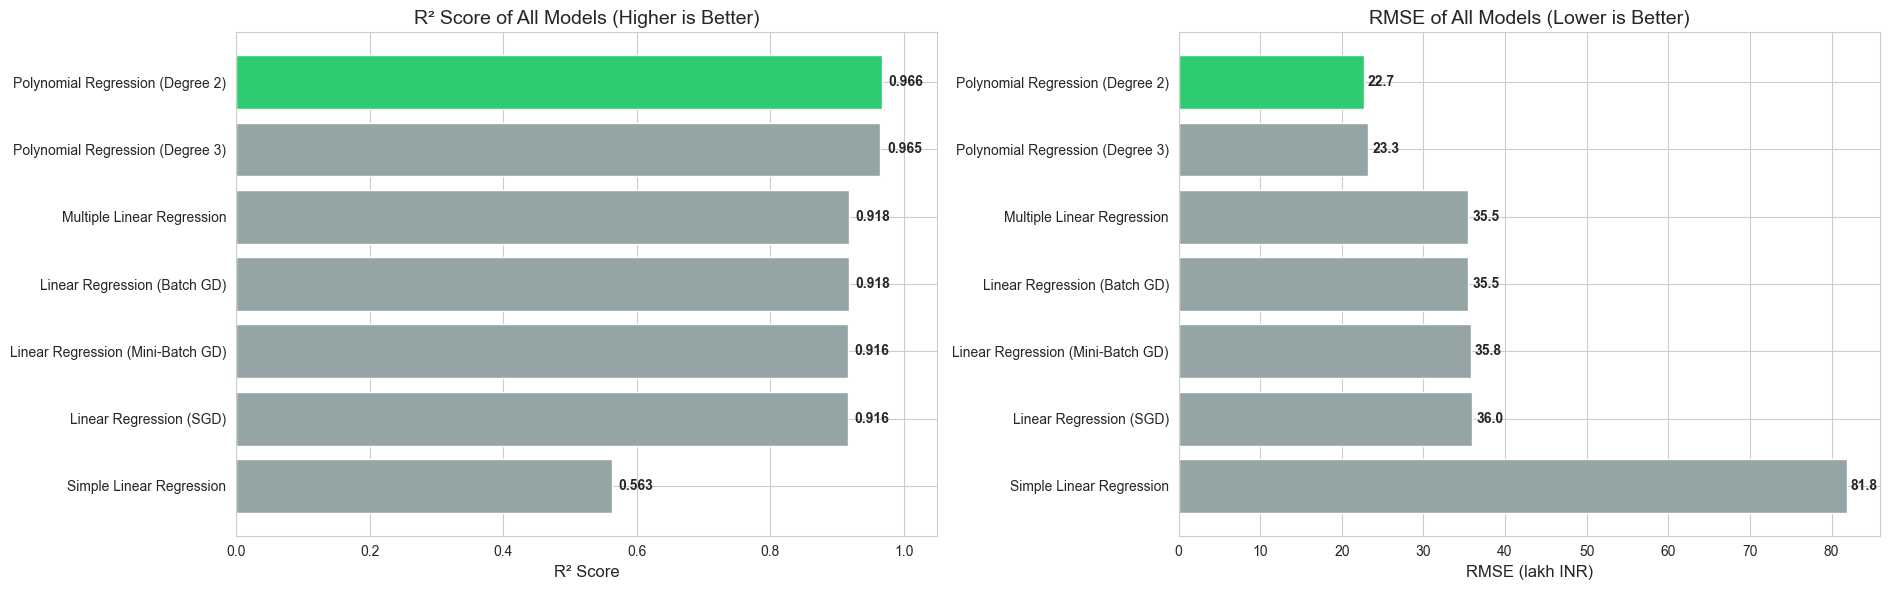

🏆 Best model: Polynomial Regression (Degree 2)


In [55]:
# (b) Final comparison graph
plot_df = final_results.sort_values("R2 Score")
best_model_final = final_results.loc[1, "Model"]
bar_colors = ["#2ecc71" if m == best_model_final else "#95a5a6" for m in plot_df["Model"]]

fig, axes = plt.subplots(1, 2, figsize=(19, 6))

axes[0].barh(plot_df["Model"], plot_df["R2 Score"], color=bar_colors)
axes[0].set_title("R² Score of All Models (Higher is Better)")
axes[0].set_xlabel("R² Score")
axes[0].set_xlim(0, 1.05)
for i, v in enumerate(plot_df["R2 Score"]):
    axes[0].text(v + 0.01, i, f"{v:.3f}", va="center", fontweight="bold")

axes[1].barh(plot_df["Model"], plot_df["RMSE (lakh)"], color=bar_colors)
axes[1].set_title("RMSE of All Models (Lower is Better)")
axes[1].set_xlabel("RMSE (lakh INR)")
for i, v in enumerate(plot_df["RMSE (lakh)"]):
    axes[1].text(v + 0.5, i, f"{v:.1f}", va="center", fontweight="bold")

plt.tight_layout()
plt.show()
print("🏆 Best model:", best_model_final)

In [56]:
# (c) Business analysis: best model kitni accurate hai?
# Error analysis of the best model (Polynomial Degree 2) on test data
err_df = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred_poly2})
err_df["Abs Error"] = (err_df["Actual"] - err_df["Predicted"]).abs()
err_df["% Error"]   = err_df["Abs Error"] / err_df["Actual"] * 100
err_df["Price Band"] = pd.qcut(err_df["Actual"], 4,
                               labels=["Low", "Medium-Low", "Medium-High", "High"])

print(f"Average house price (test)   : ₹{y_test.mean()/1e7:.2f} crore")
print(f"Average error (MAE)          : ₹{err_df['Abs Error'].mean()/1e5:.1f} lakh")
print(f"Median % error               : {err_df['% Error'].median():.1f}%")
print(f"Predictions within 10% error : {(err_df['% Error'] <= 10).mean()*100:.1f}%")
print(f"Predictions within 20% error : {(err_df['% Error'] <= 20).mean()*100:.1f}%")

band_df = err_df.groupby("Price Band", observed=True)[["Abs Error", "% Error"]].mean()
band_df["Abs Error"] = band_df["Abs Error"] / 1e5      # in lakh
band_df.columns = ["Avg Error (lakh)", "Avg % Error"]
band_df

Average house price (test)   : ₹2.41 crore
Average error (MAE)          : ₹16.6 lakh
Median % error               : 6.0%
Predictions within 10% error : 74.5%
Predictions within 20% error : 97.0%


,Avg Error (lakh),Avg % Error
Price Band,,
Low,7.99,9.05
Medium-Low,13.76,7.36
Medium-High,18.29,6.92
High,26.24,6.29


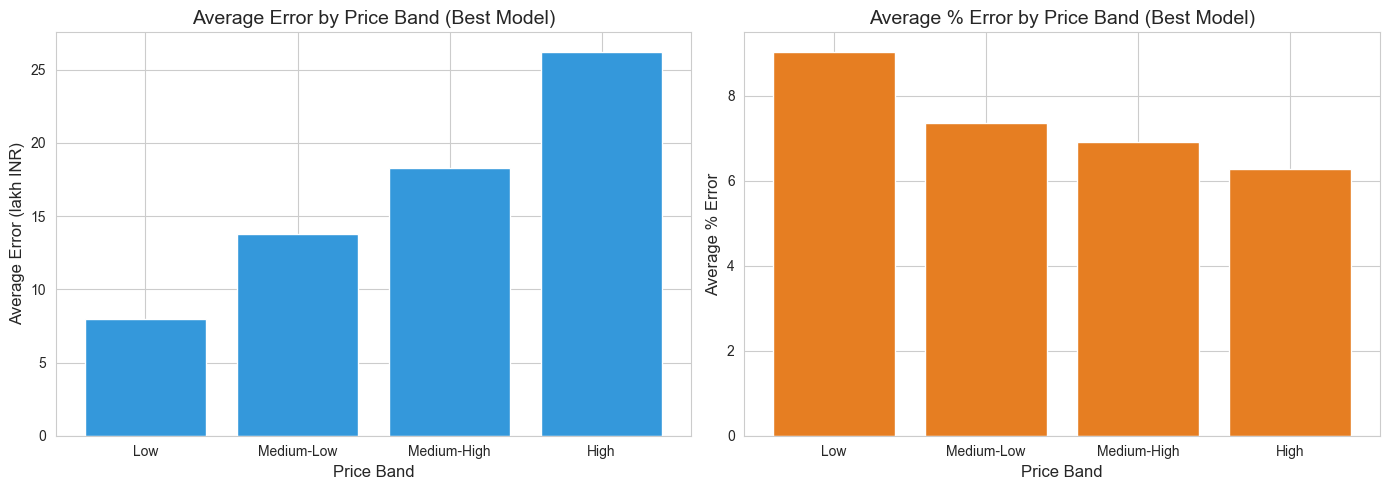

In [57]:
# Graph: error by price band
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(band_df.index.astype(str), band_df["Avg Error (lakh)"], color="#3498db")
axes[0].set_title("Average Error by Price Band (Best Model)")
axes[0].set_xlabel("Price Band")
axes[0].set_ylabel("Average Error (lakh INR)")

axes[1].bar(band_df.index.astype(str), band_df["Avg % Error"], color="#e67e22")
axes[1].set_title("Average % Error by Price Band (Best Model)")
axes[1].set_xlabel("Price Band")
axes[1].set_ylabel("Average % Error")

plt.tight_layout()
plt.show()

**Interpretation:**
- In rupees, the error grows with price: about ₹8 lakh for low-priced houses and about ₹26 lakh for high-priced houses. This matches the fan shape seen in the earlier residual plots.
- In percentage, the error is actually **highest for low-priced houses (9.0%)** and lowest for high-priced houses (6.3%), because a small rupee error is a bigger share of a small price.
- Overall, the model is accurate enough for practical use: the typical error is about 6%, and 97% of predictions are within 20% of the actual price.

## (d) Final Short Report (Markdown cell mein paste karo)
# 📄 Final Report: Predictive Insight Engine

**Goal:** Predict house prices (INR) using 10 features (area, bedrooms, bathrooms, location score, age, distance from city, lot size, garage, pool, renovation years) from a dataset of 4,200 houses. Data was split 80% train and 20% test.

## 1. Best-Performing Model and Why
**Polynomial Regression (Degree 2)** is the best model.

| Model | Test R² | RMSE (lakh) | MAE (lakh) |
|---|---|---|---|
| Simple Linear Regression | 0.563 | 81.8 | 62.9 |
| Multiple Linear Regression | 0.918 | 35.5 | 26.0 |
| **Polynomial Regression (Degree 2)** | **0.966** | **22.7** | **16.6** |
| Polynomial Regression (Degree 3) | 0.965 | 23.3 | 17.1 |

**Why it wins:**
- It has the lowest test error and the lowest total error (Bias² + Variance).
- It captures non-linear effects and feature interactions (for example area × location) that a straight-line model misses.
- Train R² (0.968) and test R² (0.966) are almost equal, and cross-validation is stable (0.966 ± 0.004), so it generalizes well.

## 2. Impact of Gradient Descent Optimization
- Batch GD, SGD and Mini-Batch GD were implemented from scratch and all reached almost the same quality as the closed-form Linear Regression (R² 0.9177, 0.9156 and 0.9163 compared with 0.9178).
- **Batch GD:** smooth and stable, but needed the most epochs (about 50).
- **SGD:** reached the minimum within 2 epochs but with a noisy path, and it was the slowest per epoch.
- **Mini-Batch GD:** best balance, with a smooth curve and fast convergence (about 6 epochs).
- Gradient Descent finds the same solution as the formula, and it is the method that scales to large datasets and complex models.

## 3. Evidence of Overfitting / Underfitting
- **Underfitting:** Simple Linear Regression (one feature) has low scores on both train (0.572) and test (0.563). Its Bias² is the highest (66.9 × 10¹²).
- **Good fit:** Polynomial Degree 2 has a train-test gap of only about 0.002.
- **Overfitting:** Degree 3 shows early signs (train 0.971, test 0.965, variance 5 times higher than Degree 2). Degree 4 (1000 features) clearly overfits: train R² 0.978 but test R² only 0.927, with variance of 226.9 × 10¹² and unstable cross-validation (std 0.043).
- Test error follows a **U-shape** with complexity, with its minimum at Degree 2.

## 4. Practical Business Interpretation
- **Key price drivers (Multiple Linear Regression, other features fixed):**
  - +1 point in location score → about **+₹30.7 lakh**
  - +100 sq.ft of area → about **+₹13.8 lakh**
  - +1 km distance from the city → about **-₹1 lakh**
  - +10 years of age → about **-₹6.6 lakh**
  - Having a pool → about **+₹4.5 lakh**
- **Accuracy in practice:** The typical error is about 6% (about ₹17 lakh on an average house price of ₹2.41 crore). About 3 out of 4 predictions are within 10% of the real price, and 97% are within 20%.
- **How the company can use it:** Quick first estimates of a fair price range, screening of under-priced or over-priced listings, and support for negotiations. It should support human valuers, not replace them.
- **Limitations:** Only 10 features (no floor, neighborhood name, market date, or house condition), and only houses of about 450 to 4,200 sq.ft, so predictions outside this range are not reliable. Errors in rupees are larger for expensive houses.
- **Next steps:** Add more features, try regularization (Ridge/Lasso) and tree-based models, and retrain regularly with fresh market data.

In [60]:
final_results.to_csv("../results/all_models_comparison.csv", index_label="Rank")
gd_results.to_csv("../results/gradient_descent_comparison.csv", index=False)
diagnostics_df.to_csv("../results/bias_variance_diagnostics.csv", index=False)
band_df.to_csv("../results/error_by_price_band.csv")

print("✅ All results saved in the 'results' folder!")

✅ All results saved in the 'results' folder!


## ✅ Final Conclusion

- We built and compared **Simple, Multiple and Polynomial Regression** models, and implemented **Batch, Stochastic and Mini-Batch Gradient Descent** from scratch to predict house prices.
- **Polynomial Regression (Degree 2)** is the best model, with **R² = 0.966**, **RMSE ≈ ₹22.7 lakh** and **MAE ≈ ₹16.6 lakh**. It gives the best balance of bias and variance.
- Simple Linear Regression **underfits** (high bias), while Polynomial Regression of Degree 3 and 4 shows **overfitting** (high variance).
- Gradient Descent reaches the same quality as the closed-form solution, and **Mini-Batch GD** gives the best balance of speed and stability.
- **Location score** and **house area** are the strongest drivers of price.
- For business use, the model predicts within about 6% error for a typical house, which is good for quick price estimates and screening. It should be used as a decision-support tool alongside expert valuation.